First, create a new conda environment named BI2025 and install the required packages from requirements.txt


In [1]:
#!conda create -n BI2025 python=3.11 -y
#!conda activate BI2025
#!pip install -r requirements.txt

In [6]:
# DO NOT MODIFY OR COPY THIS CELL!!
# Note: The only imports allowed are Python's standard library, pandas, numpy, scipy, matplotlib, seaborn and scikit-learn
import numpy as np
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import datetime
import typing
import requests
import time
import shutil
import json
import arff
from starvers.starvers import TripleStoreEngine

from sklearn.preprocessing import StandardScaler, MinMaxScaler

## Graph-based documentation preliminaries

**!!!IMPORTANT!!!**

Everytime you work on this notebook, enter your student ID in the `executed_by` variable so that the cell executions are accredited to you.

In [7]:
executed_by ='stud-id_12537811'  # Replace the digits after "id_" with your own student ID

Set your group and student IDs. Do this only once.

In [8]:
# group id for this project
group_id = "088"  # Replace the digits with your group id

ID_STUDENT_A = "12537811"  # Replace with student A's student ID
ID_STUDENT_B = "12233000"  # Replace with student B's student ID

# Students working on this notebook
student_a = f"stud-id_{ID_STUDENT_A}"  # Replace the digits after "id_" with student A's student ID
student_b = f"stud-id_{ID_STUDENT_B}"  # Replace the digits after "id_" with student B's student ID

In [9]:
# Roles. Don't change these values.
code_writer_role = "code_writer"
code_executor_role = "code_executor"

Setup the starvers API for logging your steps into our server-sided graph database.

In [10]:
get_endpoint = "https://starvers.ec.tuwien.ac.at/BI2025"
post_endpoint = "https://starvers.ec.tuwien.ac.at/BI2025/statements"
engine = TripleStoreEngine(get_endpoint, post_endpoint, skip_connection_test=True)

Use these prefixes in your notebooks. You can extend this dict with your prefixes of additional ontologies that you use in this notebook. Replace 00 with your group id

In [12]:
prefixes = {
    "xsd": "http://www.w3.org/2001/XMLSchema#",
    "rdfs": "http://www.w3.org/2000/01/rdf-schema#",
    "foaf": "http://xmlns.com/foaf/0.1/",
    "prov": "http://www.w3.org/ns/prov#",
    "sc": "https://schema.org/",
    "cr": "http://mlcommons.org/croissant/",
    "mls": "http://www.w3.org/ns/mls#",
    "mlso": "http://w3id.org/mlso",
    "siu": "https://si-digital-framework.org/SI/units/",
    "siq": "https://si-digital-framework.org/SI/quantities/",
    "qudt": "http://qudt.org/schema/qudt/",
    "unit": "http://qudt.org/vocab/unit/",
    "": f"https://starvers.ec.tuwien.ac.at/BI2025/{group_id}/",
}

prefix_header = "\n".join([f"PREFIX {k}: <{v}>" for k, v in prefixes.items()]) + "\n\n"

Ontologies to use
* Provenance of the experiment process
    * PROV-O: 
        * doc: https://www.w3.org/TR/prov-o/
        * serialization: https://www.w3.org/ns/prov-o
* Data used and created
    * schema.org - Dataset: 
        * doc: https://schema.org/Dataset
        * serialization: https://schema.org/version/latest/schemaorg-current-https.ttl
    * Crossaint
        * doc: https://docs.mlcommons.org/croissant/docs/croissant-spec.html
        * serialization: https://github.com/mlcommons/croissant/blob/main/docs/croissant.ttl
* ML experiments performed
    * MLSO: 
        * doc: https://github.com/dtai-kg/MLSO
        * doc: https://dtai-kg.github.io/MLSO/#http://w3id.org/
        * serialization: https://dtai-kg.github.io/MLSO/ontology.ttl
* Measurements, Metrics, Units
    * QUDT
        * doc:https://qudt.org/
        * doc: https://github.com/qudt/qudt-public-repo
        * serialization: https://github.com/qudt/qudt-public-repo/blob/main/src/main/rdf/schema/SCHEMA_QUDT.ttl
    * SI Digital Framework
        * doc: https://github.com/TheBIPM/SI_Digital_Framework/blob/main/SI_Reference_Point/docs/README.md
        * doc: https://si-digital-framework.org/
        * doc: https://si-digital-framework.org/SI
        * serialization: https://github.com/TheBIPM/SI_Digital_Framework/blob/main/SI_Reference_Point/TTL/si.ttl
    * Quantities and Units
        * doc: https://www.omg.org/spec/Commons
        * serialization: https://www.omg.org/spec/Commons/QuantitiesAndUnits.ttl

Use this function to record execution times.

In [13]:
def now() -> str:
    """
    Returns the current time in ISO 8601 format with UTC timezone in the following format:
    YYYY-MM-DDTHH:MM:SS.sssZ
    """
    timestamp = datetime.datetime.now(datetime.timezone.utc)
    timestamp_formated = timestamp.strftime("%Y-%m-%dT%H:%M:%S.%f")[:-3] + "Z"

    return timestamp_formated

Register yourself in the Knowledge Graph using ProvO. Change the given name, family name and immatriculation number to reflect your own data.

In [14]:
# Ontologies used: foaf, prov, IAO
reigstration_triples_a = [
    f":{student_a} rdf:type foaf:Person .",
    f":{student_a} rdf:type prov:Agent .",
    f':{student_a} foaf:givenName "Maria" .',
    f':{student_a} foaf:familyName "Salmasian" .',
    f":{student_a} <http://vivoweb.org/ontology/core#identifier> :{student_a} .",
    f":{student_a} rdf:type <http://purl.obolibrary.org/obo/IAO_0000578> .",
    f':{student_a} <http://www.w3.org/2000/01/rdf-schema#label> "Immatriculation number" .',
    f':{student_a} <http://purl.obolibrary.org/obo/IAO_0000219> "{ID_STUDENT_A}"^^xsd:string .',
]

reigstration_triples_b = [
    f":{student_b} rdf:type foaf:Person .",
    f":{student_b} rdf:type prov:Agent .",
    f':{student_b} foaf:givenName "Brais" .',
    f':{student_b} foaf:familyName "Guardado Collazo" .',
    f":{student_b} <http://vivoweb.org/ontology/core#identifier> :{student_b} .",
    f":{student_b} rdf:type <http://purl.obolibrary.org/obo/IAO_0000578> .",
    f':{student_b} <http://www.w3.org/2000/01/rdf-schema#label> "Immatriculation number" .',
    f':{student_b} <http://purl.obolibrary.org/obo/IAO_0000219> "{ID_STUDENT_B}"^^xsd:string .',
]

role_triples = [
    f":{code_writer_role} rdf:type prov:Role .",
    f":{code_executor_role} rdf:type prov:Role .",
]


engine.insert(reigstration_triples_a, prefixes=prefixes)
engine.insert(reigstration_triples_b, prefixes=prefixes)
engine.insert(role_triples, prefixes=prefixes)

**What not do do**

Do not use [blank nodes](https://www.w3.org/wiki/BlankNodes).

PROV-O uses blank nodes to connect multiple elements with each other.
Such blank nodes (such as _:association) should not be used.
Instead, assign a fixed node ID such as
:5119fcd7-b571-41e0-9464-a37c7be0f574 by generating them outside of the
notebook.
We suggest that, for each setting where such a blank node is needed to
connect multiple elements, you create a unique hash (using uuid.uuid4())
and keep this as hard-coded identifier for the blank node. The template
notebook contains examples of this. Do *not* use these provided values,
as otherwise, your provenance documentations will all be connected via
these identifiers!
Also, do not generate them dynamically in every cell execution, e.g. by
using uuid.uuid4() in a cell. This would generate many new linking nodes
for connecting the same elements.
Compute one for each node (cell) where you need them and make sure to
use the same one on each re-execution of the notebook.

In [15]:
dry_bean_data_path = os.path.join("data", "Dry_Bean_Dataset.arff")

## Business Understanding 

In [16]:
## Each Activity that follows is part of the Business Understanding Phase

business_understanding_phase_executor = [
    ":business_understanding_phase rdf:type prov:Activity .",
    ':business_understanding_phase rdfs:label "Business Understanding Phase" .',  ## Phase 1: Business Understanding
]
engine.insert(business_understanding_phase_executor, prefixes=prefixes)


In [17]:
#############################################
# Documentation
#############################################

data_src_and_scenario_comment = """
The data source is the Dry Bean Dataset, manually collected by the department of computer engineering of the Selcuk University, Turkey. It contains 13611 instances of 7 different dry bean varieties processed into 16 different morphological features (e.g. area, perimeter, major axis length...) via computer vision.

According to the literature, dry beans are the most important and most produced pulses over the world. Assessment of the best seed is the main problem for dry bean producers and markets. Traditionally, bean classification is performed manually, which is a difficult process as well as very time consuming and inefficient at scale. Misclassification errors can also occur, which lead to quality inconsistencies and customer rejections.
"""

business_objectives_comment = """
Two main business objectives can be identified: to automate the dry bean classification problem, cutting operational costs and to minimize misclassification errors induced by this sorting process.
"""

business_success_criteria_comment = """
Some business success criteria tied to the objectives:
- Reduce customer returns by 5%.
- Cut labor costs by 30%.
- 50% increase in sorting speed.
"""

data_mining_goals_comment = """
We propose the following goals:
- Training of two multiclass classification models.
- If model supports it, quantify feature importance and explainability.
"""

data_mining_success_criteria_comment = """
- Trained classifier achieves >95% accuracy.
- Identification of the 5 most important features for classification.
"""

ai_risk_aspects_comment = """
We deem the task of dry bean classification relatively harmless in terms of possible AI Risks identified by the EU AI Act. However, some considerations must be noted:

- Data bias and generalization: the dataset originates from a controlled set of images. Trained models may rely on specific lighting conditions or zoom/scale, failing when faced with real world production environments
- ML Security: computer vision backed models are susceptible to be targeted by adversarial attacks. In this context, a successful attack (intentional or not) could trigger a misclassification, contaminating the batch.
"""


bu_ass_uuid_executor = "b0511130-e18c-49b5-ad82-0c2fac98d7e4"  # Generate once
business_understanding_executor = [
    ":business_understanding rdf:type prov:Activity .",
    ":business_understanding sc:isPartOf :business_understanding_phase .",  # Connect Activity to Parent Business Understanding Phase Activity
    f":business_understanding prov:qualifiedAssociation :{bu_ass_uuid_executor} .",
    f":{bu_ass_uuid_executor} prov:agent :{executed_by} .",
    f":{bu_ass_uuid_executor} rdf:type prov:Association .",
    f":{bu_ass_uuid_executor} prov:hadRole :{code_executor_role} .",
]
engine.insert(business_understanding_executor, prefixes=prefixes)


business_understanding_data_executor = [
    # 1a
    ":bu_data_source_and_scenario rdf:type prov:Entity .",
    ":bu_data_source_and_scenario prov:wasGeneratedBy :business_understanding .",
    ':bu_data_source_and_scenario rdfs:label "1a Data Source and Scenario" .',
    f':bu_data_source_and_scenario rdfs:comment """{data_src_and_scenario_comment}""" .',
    # 1b
    ":bu_business_objectives rdf:type prov:Entity .",
    ":bu_business_objectives prov:wasGeneratedBy :business_understanding .",
    ':bu_business_objectives rdfs:label "1b Business Objectives" .',
    f':bu_business_objectives rdfs:comment """{business_objectives_comment}""" .',
    # 1c
    ":bu_business_success_criteria rdf:type prov:Entity .",
    ":bu_business_success_criteria prov:wasGeneratedBy :business_understanding .",
    ':bu_business_success_criteria rdfs:label "1c Business Success Criteria" .',
    f':bu_business_success_criteria rdfs:comment """{business_success_criteria_comment}""" .',
    # 1d
    ":bu_data_mining_goals rdf:type prov:Entity .",
    ":bu_data_mining_goals prov:wasGeneratedBy :business_understanding .",
    ':bu_data_mining_goals rdfs:label "1d Data Mining Goals" .',
    f':bu_data_mining_goals rdfs:comment """{data_mining_goals_comment}""" .',
    # 1e
    ":bu_data_mining_success_criteria rdf:type prov:Entity .",
    ":bu_data_mining_success_criteria prov:wasGeneratedBy :business_understanding .",
    ':bu_data_mining_success_criteria rdfs:label "1e Data Mining Success Criteria" .',
    f':bu_data_mining_success_criteria rdfs:comment """{data_mining_success_criteria_comment}""" .',
    # 1f
    ":bu_ai_risk_aspects rdf:type prov:Entity .",
    ":bu_ai_risk_aspects prov:wasGeneratedBy :business_understanding .",
    ':bu_ai_risk_aspects rdfs:label "1f AI risk aspects" .',
    f':bu_ai_risk_aspects rdfs:comment """{ai_risk_aspects_comment}""" .',
]
engine.insert(business_understanding_data_executor, prefixes=prefixes)

## Data Understanding

The following pseudo-code & pseudo-documentation may be used as a hint.

In [18]:
## Each Activity that follows is part of the Data Understanding Phase

business_understanding_phase_executor = [
    ":data_understanding_phase rdf:type prov:Activity .",
    ':data_understanding_phase rdfs:label "Data Understanding Phase" .',
]
engine.insert(business_understanding_phase_executor, prefixes=prefixes)


In [19]:
def load_dry_bean_data() -> pd.DataFrame:
    """
    Load the dry bean data from the ARFF file and return it as a pandas DataFrame.
    """
    # Load the ARFF file
    with open(dry_bean_data_path, "r") as f:
        data = arff.load(f)
    return pd.DataFrame(data["data"], columns=[attr[0] for attr in data["attributes"]])

In [21]:
load_bean_data_code_writer = student_a

start_time_ld = now()
data = load_dry_bean_data()
end_time_ld = now()

display(data.head())

#############################################
# Documentation
#############################################

# Now document the raw data and the loaded data using appropriate ontologies.

# Always add these triples for every activity to define the executor!
ld_ass_uuid_executor = "d040a1d1-84ed-4f2c-b206-073f10eb37f8"  # Generate once
load_dry_bean_data_executor = [
    f":load_dry_bean_data prov:qualifiedAssociation :{ld_ass_uuid_executor} .",
    f":{ld_ass_uuid_executor} prov:agent :{executed_by} .",
    f":{ld_ass_uuid_executor} rdf:type prov:Association .",
    f":{ld_ass_uuid_executor} prov:hadRole :{code_executor_role} .",
]
engine.insert(load_dry_bean_data_executor, prefixes=prefixes)

ld_ass_uuid_writer = "700c15df-b8c4-462b-8869-3227bc6a5b78"  # Generate once
ld_report = """
Load all dry bean data. 
"""
load_dry_bean_data_activity = [
    ":load_dry_bean_data rdf:type prov:Activity .",
    ":load_dry_bean_data sc:isPartOf :data_understanding_phase .",
    ":load_dry_bean_data rdfs:comment 'Data Understanding' .",
    f':load_dry_bean_data rdfs:comment """{ld_report}""" .',
    f':load_dry_bean_data prov:startedAtTime "{start_time_ld}"^^xsd:dateTime .',
    f':load_dry_bean_data prov:endedAtTime "{end_time_ld}"^^xsd:dateTime .',
    f":load_dry_bean_data prov:qualifiedAssociation :{ld_ass_uuid_writer} .",
    f":{ld_ass_uuid_writer} prov:agent :{load_bean_data_code_writer} .",
    f":{ld_ass_uuid_writer} rdf:type prov:Association .",
    f":{ld_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    # INPUT of activity
    ":load_dry_bean_data prov:used :raw_data .",
    ":load_dry_bean_data prov:used :raw_data_path .",
    ":raw_data rdf:type prov:Entity .",
    ":raw_data_path rdf:type prov:Entity .",
    ":raw_data prov:wasDerivedFrom :raw_data_path .",
    # OUTPUT of activity
    ":data rdf:type prov:Entity .",
    ":data prov:wasGeneratedBy :load_dry_bean_data .",
    ":data prov:wasDerivedFrom :raw_data .",
]
engine.insert(load_dry_bean_data_activity, prefixes=prefixes)

# Further descibe the raw data using Croissant
raw_data_triples = [
    ":raw_data rdf:type sc:Dataset .",
    ":raw_data sc:name 'Dry Bean Dataset' .",
    ":raw_data sc:description 'Morphological features describing seven dry bean classes.' .",
    ":raw_data sc:licence 'https://creativecommons.org/licenses/by/4.0/legalcode' .",
    ":raw_data sc:url 'https://doi.org/10.24432/C50S4B' .",
    ":raw_data sc:citeAs '@misc{dry_bean_602,title={{Dry Bean}}, year={2020}, howpublished={UCI Machine Learning Repository}, note={{DOI: https:/doi.org/10.24432/C50S4B}}' .",
    # Continue with futher information about the dataset...
    ":dry_bean_arff rdf:type cr:FileObject .",
    ":dry_bean_arff sc:name 'dry_bean.arff' .",
    ":dry_bean_arff sc:encodingFormat 'text/arff' .",
    ":raw_data sc:distribution :dry_bean_arff .",
    # Continue with further information about the distribution...
    ":raw_recordset rdf:type cr:RecordSet .",
    ":raw_recordset sc:name 'Table of dry bean data' .",
    ":raw_recordset cr:source :dry_bean_arff .",
    ":raw_data cr:recordSet :raw_recordset .",
    # Continue with further information about the recordset...
    ":raw_recordset cr:field :field_area .",
    ":field_area rdf:type cr:Field .",
    ":field_area sc:name 'Area' .",
    ":field_area qudt:abbreviation 'A' .",
    ":field_area sc:description 'The area of a bean zone and the number of pixels within its boundaries.' .",
    ":field_area qudt:Unit unit:PIXEL .",
    ":field_area cr:dataType xsd:integer .",
    ###
    ":raw_recordset cr:field :field_perimeter .",
    ":field_perimeter rdf:type cr:Field .",
    ":field_perimeter sc:name 'Perimeter' .",
    ":field_perimeter qudt:abbreviation 'P' .",
    ":field_perimeter sc:description 'Bean circumference is defined as the length of its border.' .",
    ":field_perimeter cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_major_axis_length .",
    ":field_major_axis_length rdf:type cr:Field .",
    ":field_major_axis_length sc:name 'Major axis length' .",
    ":field_major_axis_length qudt:abbreviation 'L' .",
    ":field_major_axis_length sc:description 'The distance between the ends of the longest line that can be drawn from a bean.' .",
    ":field_major_axis_length cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_minor_axis_length .",
    ":field_minor_axis_length rdf:type cr:Field .",
    ":field_minor_axis_length sc:name 'Minor axis length' .",
    ":field_minor_axis_length qudt:abbreviation 'l' .",
    ":field_minor_axis_length sc:description 'The distance of the longest line that can be drawn from the bean while standing perpendicular to the main axis.' .",
    ":field_minor_axis_length cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_aspect_ratio .",
    ":field_aspect_ratio rdf:type cr:Field .",
    ":field_aspect_ratio sc:name 'Aspect ratio' .",
    ":field_aspect_ratio qudt:abbreviation 'K' .",
    ":field_aspect_ratio sc:description 'Defines the relationship between the major and minor axis lengths.' .",
    ":field_aspect_ratio qudt:expression 'K = L / l' .",
    # ":field_aspect_ratio qudt:relation :field_major_axis_length, :field_minor_axis_length .",
    ":field_aspect_ratio cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_eccentricity .",
    ":field_eccentricity rdf:type cr:Field .",
    ":field_eccentricity sc:name 'Eccentricity' .",
    ":field_eccentricity qudt:abbreviation 'Ec' .",
    ":field_eccentricity sc:description 'Eccentricity of the ellipse having the same moments as the region.' .",
    ":field_eccentricity cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_convex_area .",
    ":field_convex_area rdf:type cr:Field .",
    ":field_convex_area sc:name 'Convex area' .",
    ":field_convex_area qudt:abbreviation 'C' .",
    ":field_convex_area sc:description 'Number of pixels in the smallest convex polygon that can contain the area of a bean seed.' .",
    ":field_convex_area cr:dataType xsd:integer .",
    ###
    ":raw_recordset cr:field :field_equivalent_diameter .",
    ":field_equivalent_diameter rdf:type cr:Field .",
    ":field_equivalent_diameter sc:name 'Equivalent diameter' .",
    ":field_equivalent_diameter qudt:abbreviation 'Ed' .",
    ":field_equivalent_diameter sc:description 'The diameter of a circle having the same area as a bean seed area.' .",
    ":field_equivalent_diameter qudt:expression 'Ed = 2 * sqrt(A / pi)' .",
    # ":field_equivalent_diameter qudt:relation :field_area .",
    ":field_equivalent_diameter cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_extent .",
    ":field_extent rdf:type cr:Field .",
    ":field_extent sc:name 'Extent' .",
    ":field_extent qudt:abbreviation 'Ex' .",
    ":field_extent sc:description 'The ratio of the pixels in the bounding box to the bean area.' .",
    ":field_extent qudt:expression 'Ex = A / Area of bounding rectangle' .",
    # ":field_extent qudt:relation :field_area .",
    ":field_extent cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_solidity .",
    ":field_solidity rdf:type cr:Field .",
    ":field_solidity sc:name 'Solidity' .",
    ":field_solidity sc:alternateName 'Convexity' .",
    ":field_solidity qudt:abbreviation 'S' .",
    ":field_solidity sc:description 'The ratio of the pixels in the convex shell to those found in beans.' .",
    ":field_solidity qudt:expression 'S = A / C' .",
    # ":field_solidity qudt:relation :field_area, :field_convex_area .",
    ":field_solidity cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_roundness .",
    ":field_roundness rdf:type cr:Field .",
    ":field_roundness sc:name 'Roundness' .",
    ":field_roundness qudt:abbreviation 'R' .",
    ":field_roundness sc:description 'Ratio of area over the squared of the perimeter' .",
    ":field_roundness qudt:expression 'R = 4 * pi * A / P^2' .",
    # ":field_roundness qudt:relation :field_area, :field_perimeter .",
    ":field_roundness cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_compactness .",
    ":field_compactness rdf:type cr:Field .",
    ":field_compactness sc:name 'Compactness' .",
    ":field_compactness qudt:abbreviation 'CO' .",
    ":field_compactness sc:description 'Measures the roundness of an object' .",
    ":field_compactness qudt:expression 'CO = Ed / P' .",
    # ":field_compactness qudt:relation :field_equivalent_diameter, :field_perimeter .",
    ":field_compactness cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_shpf1 .",
    ":field_shpf1 rdf:type cr:Field .",
    ":field_shpf1 sc:name 'Shape Factor 1' .",
    # ":field_shpf1 sc:description 'This is a date field of...' .",
    ":field_shpf1 qudt:expression '= L / A' .",
    # ":field_shpf1 qudt:relation :field_major_axis_length, :field_area .",
    ":field_shpf1 cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_shpf2 .",
    ":field_shpf2 rdf:type cr:Field .",
    ":field_shpf2 sc:name 'Shape Factor 2' .",
    # ":field_shpf2 sc:description 'This is a date field of...' .",
    ":field_shpf2 qudt:expression '= l / A' .",
    # ":field_shpf2 qudt:relation :field_minor_axis_length, :field_area .",
    ":field_shpf2 cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_shpf3 .",
    ":field_shpf3 rdf:type cr:Field .",
    ":field_shpf3 sc:name 'Shape Factor 3' .",
    # ":field_shpf3 sc:description 'This is a date field of...' .",
    ":field_shpf3 qudt:expression '= A / (L^2 / 4 * pi)' .",
    # ":field_shpf3 qudt:relation :field_area, :field_major_axis_length .",
    ":field_shpf3 cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_shpf4 .",
    ":field_shpf4 rdf:type cr:Field .",
    ":field_shpf4 sc:name 'Shape Factor 4' .",
    # ":field_shpf4 sc:description 'This is a date field of...' .",
    ":field_shpf4 qudt:expression '= A / (L / 2 * l / 2 * pi)' .",
    # ":field_shpf4 qudt:relation :field_area, :field_major_axis_length, :field_minor_axis_length .",
    ":field_shpf4 cr:dataType xsd:double .",
    ###
    ":raw_recordset cr:field :field_class .",
    ":field_class rdf:type cr:Field .",
    ":field_class sc:name 'Class' .",
    ":field_class sc:description 'The bean variety' .",
    ":field_class cr:dataType xsd:string .",
]
engine.insert(raw_data_triples, prefixes=prefixes)

# Also the output of the load activity is a dataset that can be described with Croissant
data_triples = [
    ":data rdf:type sc:Dataset .",
    # ...
    ":recordset rdf:type cr:RecordSet .",
    # ...
    ":data cr:recordSet :recordset .",
    # ...
    # Fields can also be reused
    ":recordset cr:field :field_area .",
    ":recordset cr:field :field_perimeter .",
    ":recordset cr:field :field_major_axis_length .",
    ":recordset cr:field :field_minor_axis_length .",
    ":recordset cr:field :field_aspect_ratio .",
    ":recordset cr:field :field_eccentricity .",
    ":recordset cr:field :field_convex_area .",
    ":recordset cr:field :field_equivalent_diameter .",
    ":recordset cr:field :field_extent .",
    ":recordset cr:field :field_solidity .",
    ":recordset cr:field :field_roundness .",
    ":recordset cr:field :field_compactness .",
    ":recordset cr:field :field_shpf1 .",
    ":recordset cr:field :field_shpf2 .",
    ":recordset cr:field :field_shpf3 .",
    ":recordset cr:field :field_shpf4 .",
    ":recordset cr:field :field_class .",
]
engine.insert(data_triples, prefixes=prefixes)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [22]:
def check_missing_values(df: pd.DataFrame) -> pd.Series:
    """
    Check for missing values in the DataFrame and return a Series with the count of missing values per column.
    """
    return df.isnull().sum()

In [23]:
check_missing_values(data)

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

**Continue with other tasks of the Data Understanding phase such as checking the distribution, skewness, plausibility of values, etc...**

In [26]:
def class_imbalance(df: pd.DataFrame):
    """
    Visualizes the class distribution in the dataset.
    """
    plt.figure(figsize=(10, 6))
    sns.countplot(x="Class", data=df)
    plt.title("Class Distribution")
    plt.show()

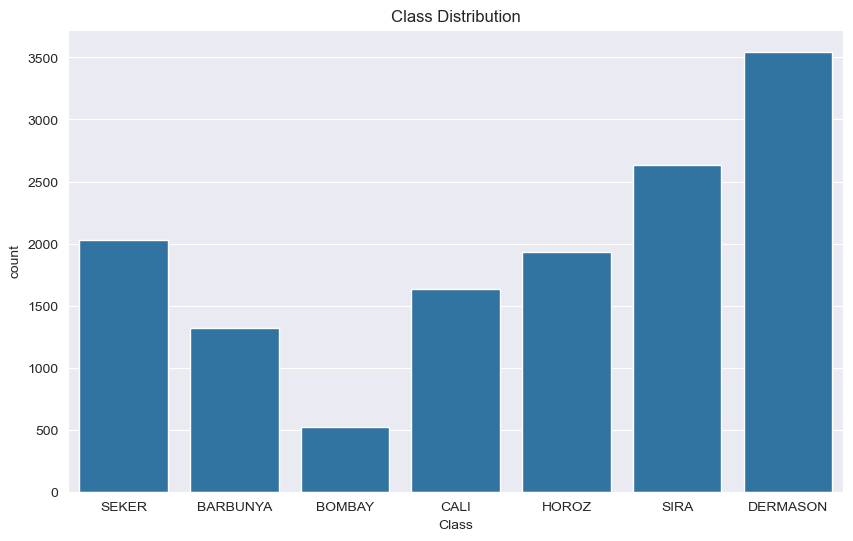

In [27]:
class_imbalance(data)

In [28]:
def plot_correlation_matrix(df: pd.DataFrame):
    """
    For all numerical values, plots correlation matrix for the given DataFrame.
    """
    corr = df.select_dtypes(include=[np.number]).corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, cmap="vlag", annot=True, fmt=".2f")
    plt.title("Correlation Matrix")
    plt.xticks(ticks=np.arange(len(corr.columns)), labels=corr.columns, rotation=90)
    plt.yticks(ticks=np.arange(len(corr.index)), labels=corr.index)
    plt.show()


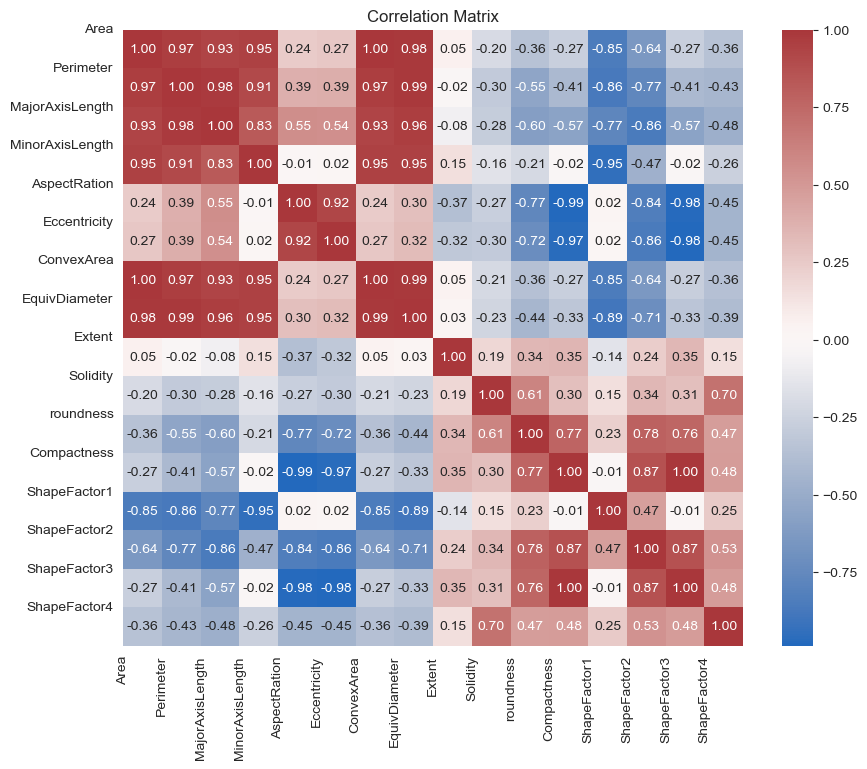

In [29]:
plot_correlation_matrix(data)

In [30]:
def histograms(df: pd.DataFrame):
    """
    Just simple histograms for all numerical columns in the DataFrame.
    """
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols].hist(bins=30, figsize=(15, 10))
    plt.tight_layout()
    plt.show()


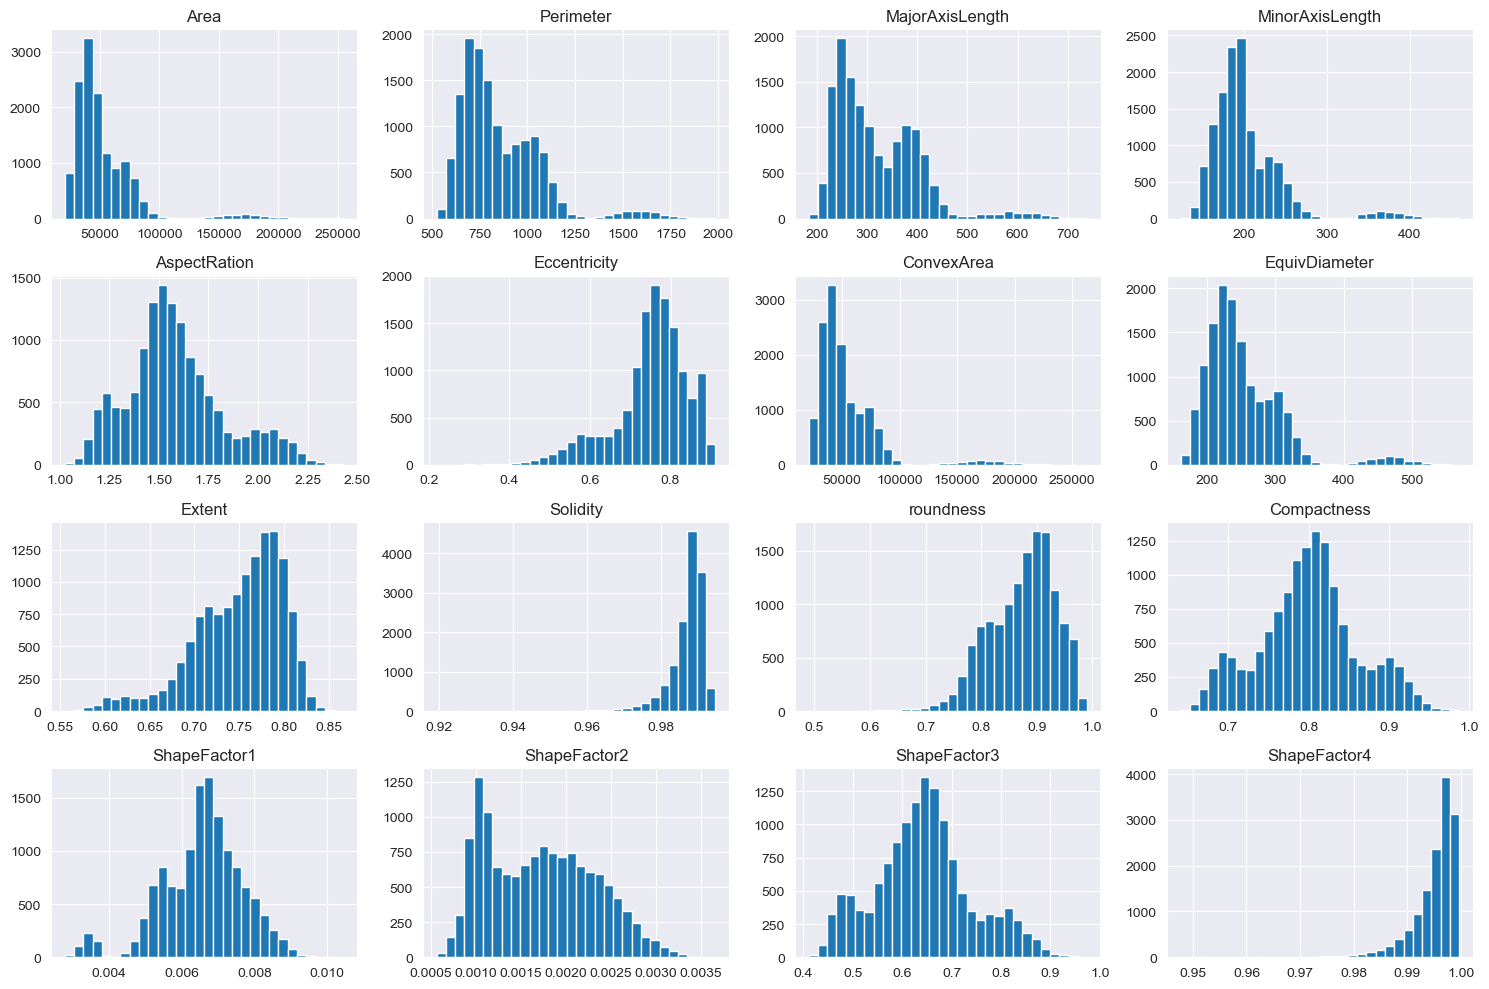

In [31]:
histograms(data)

In [32]:
def box_plots_per_class(df: pd.DataFrame):
    """
    Shows box plots in 2x1 grids for each numerical feature per class.
    """
    num_cols = df.select_dtypes(include=[np.number]).columns
    class_col = "Class"
    for col in num_cols:
        plt.figure(figsize=(10, 6))
        sns.boxplot(y=class_col, x=col, data=df)
        plt.title(f"Box Plot of {col} by {class_col}")
        plt.grid()
        plt.show()


def violin_plots_per_class(df: pd.DataFrame):
    """
    Shows violin plots in 2x1 grids for each numerical feature per class.
    """
    num_cols = df.select_dtypes(include=[np.number]).columns
    class_col = "Class"
    for col in num_cols:
        plt.figure(figsize=(10, 6))
        sns.violinplot(y=class_col, x=col, data=df)
        plt.title(f"Violin Plot of {col} by {class_col}")
        plt.grid()
        plt.show()

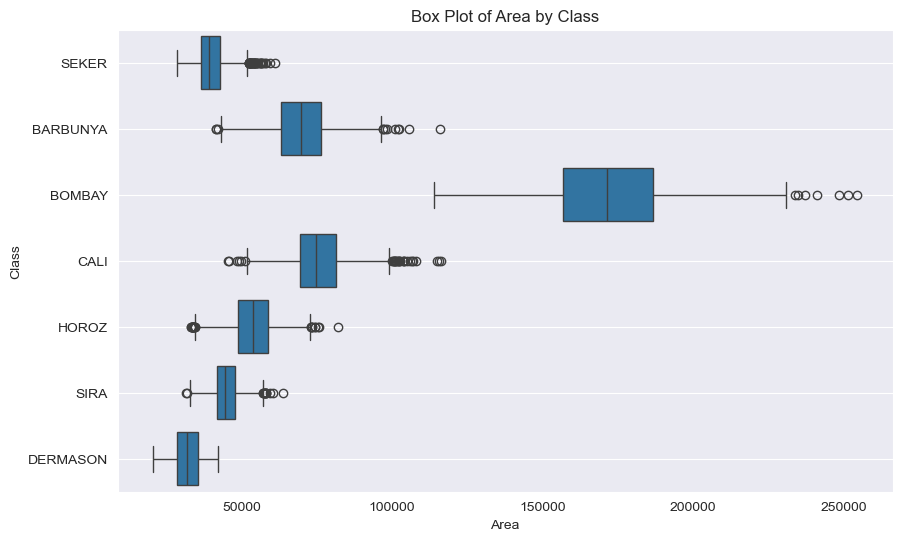

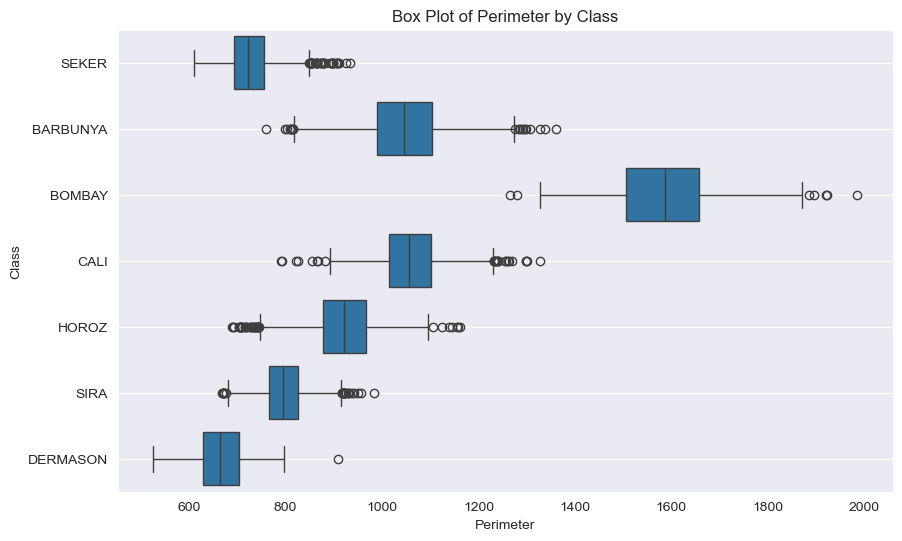

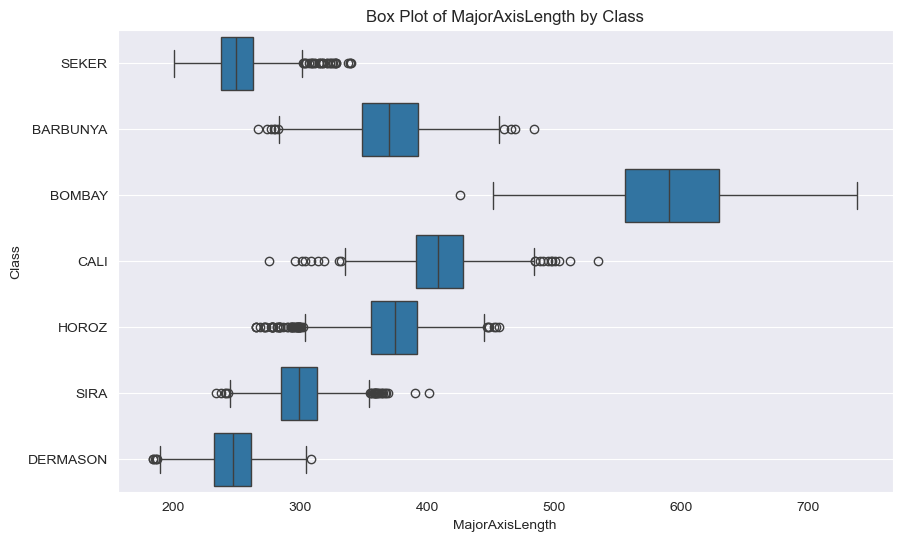

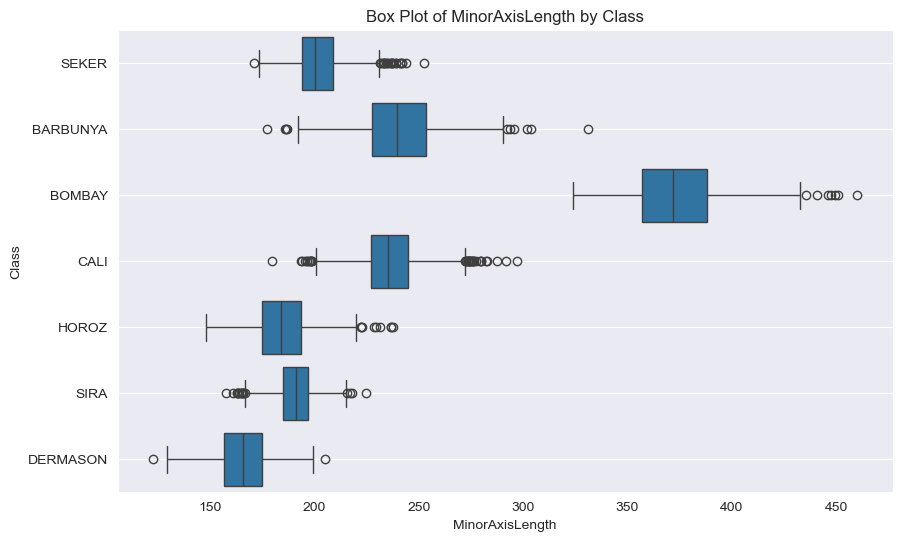

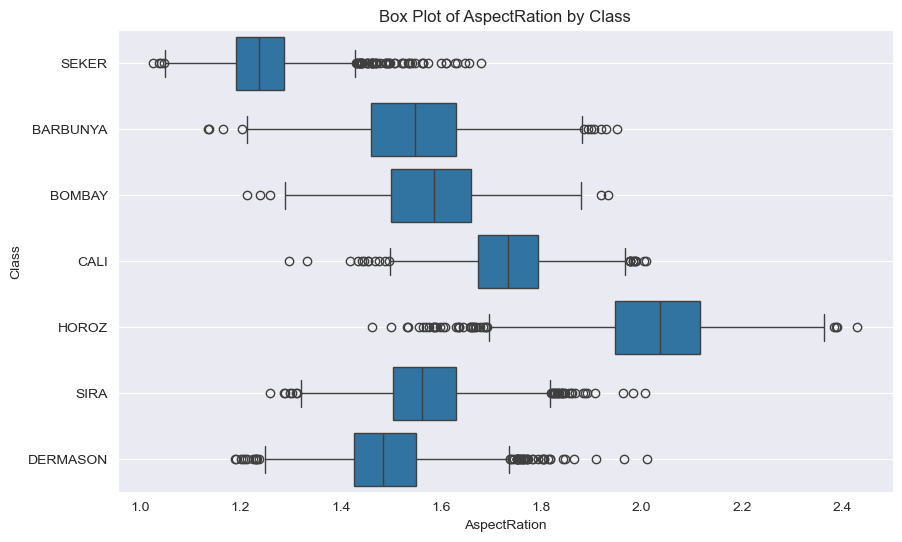

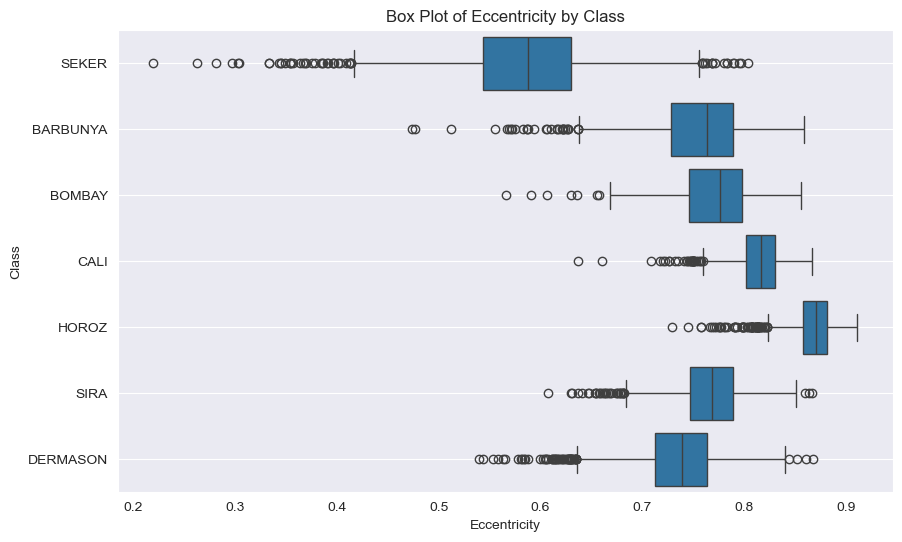

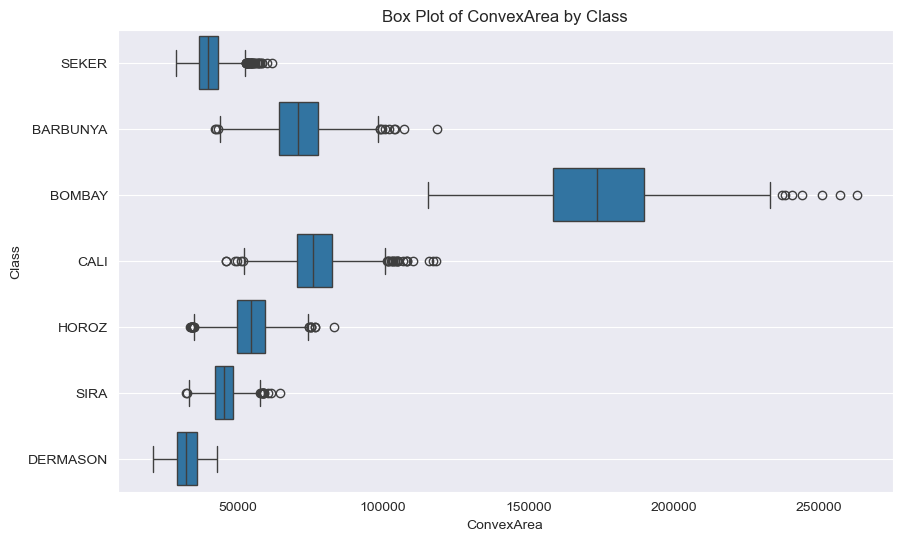

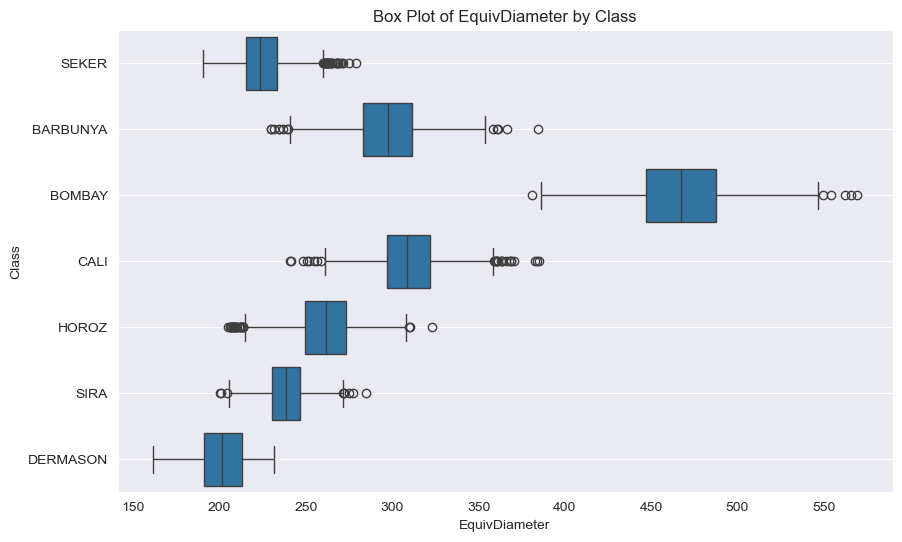

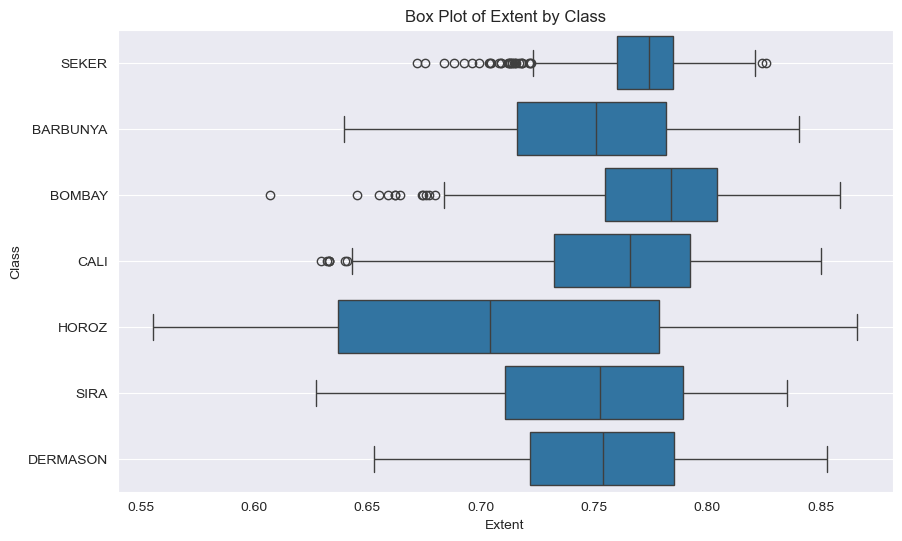

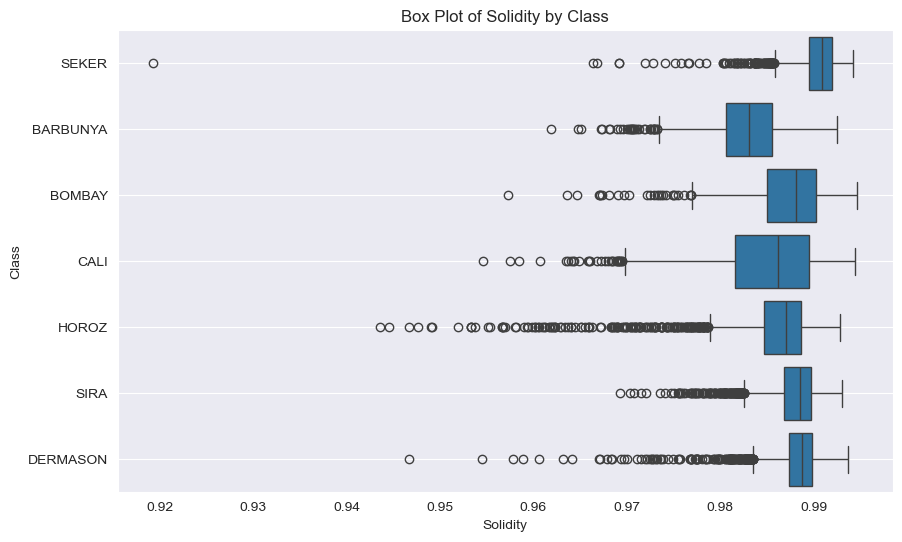

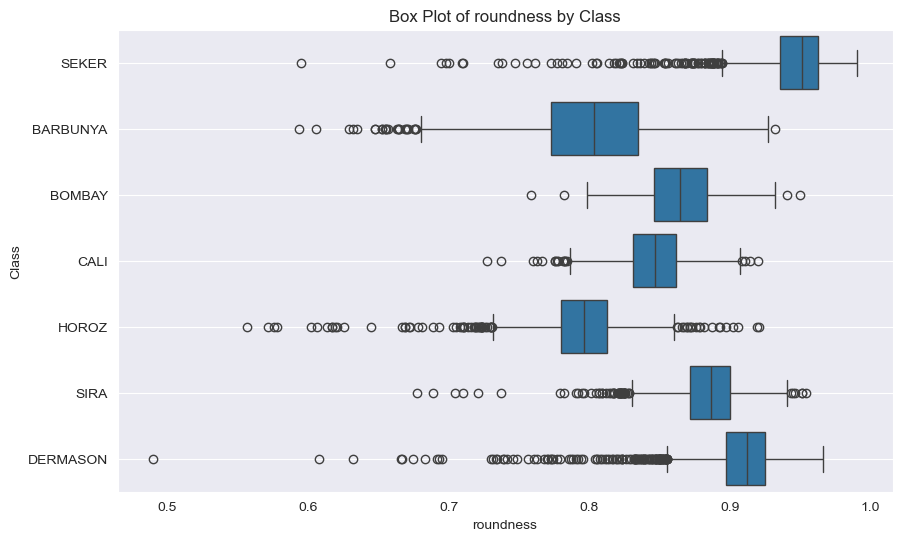

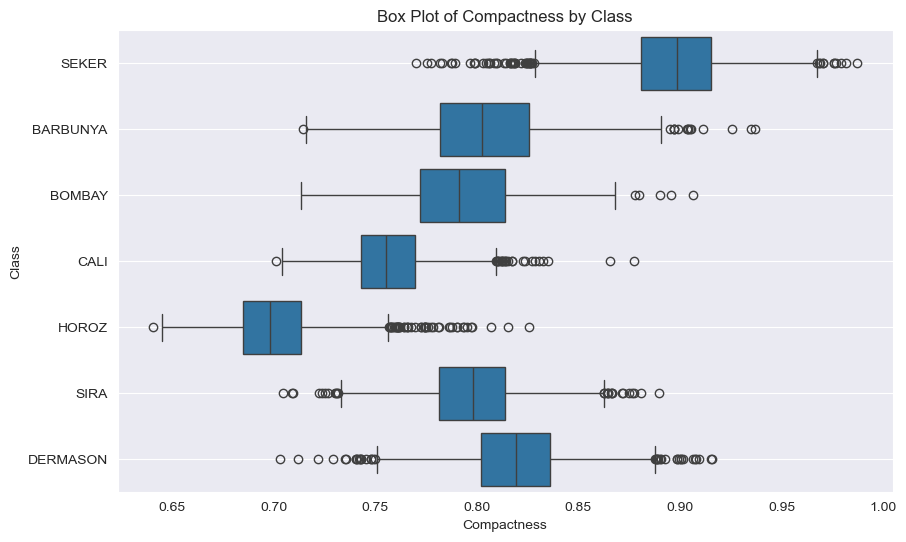

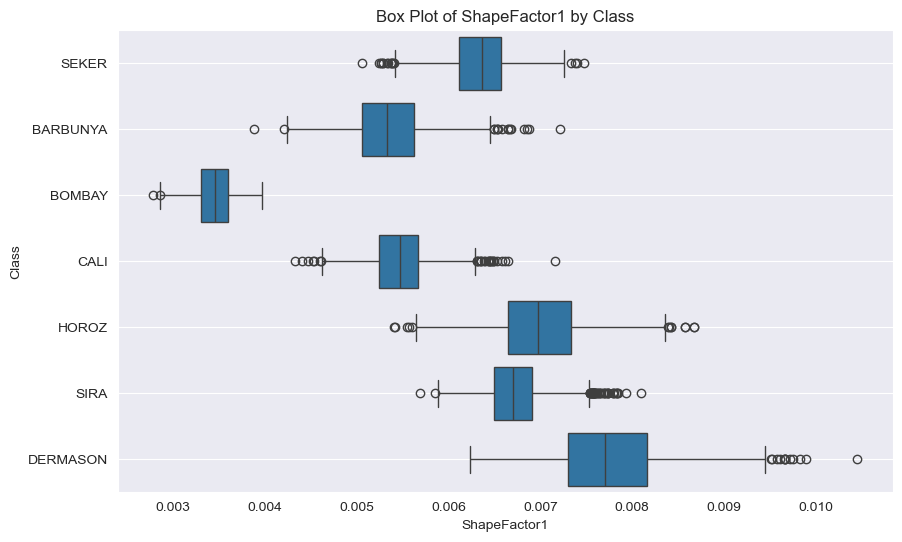

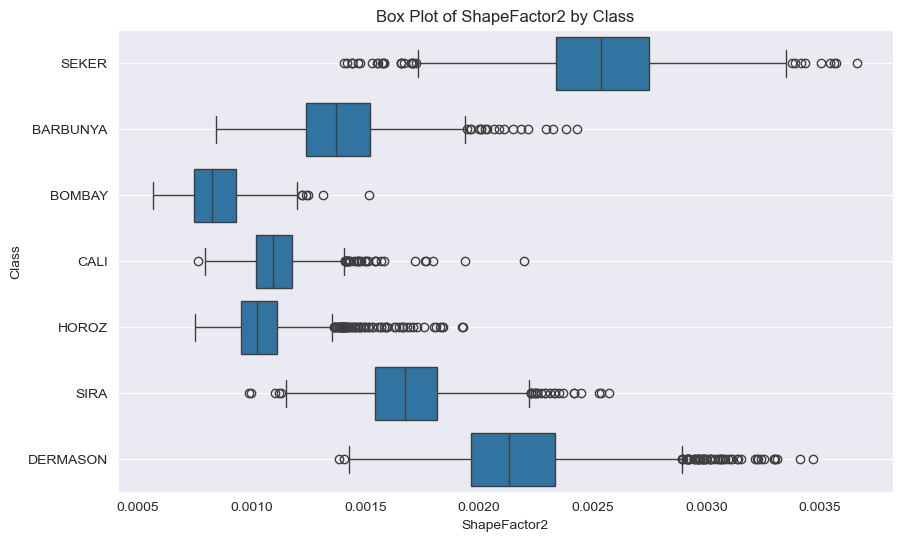

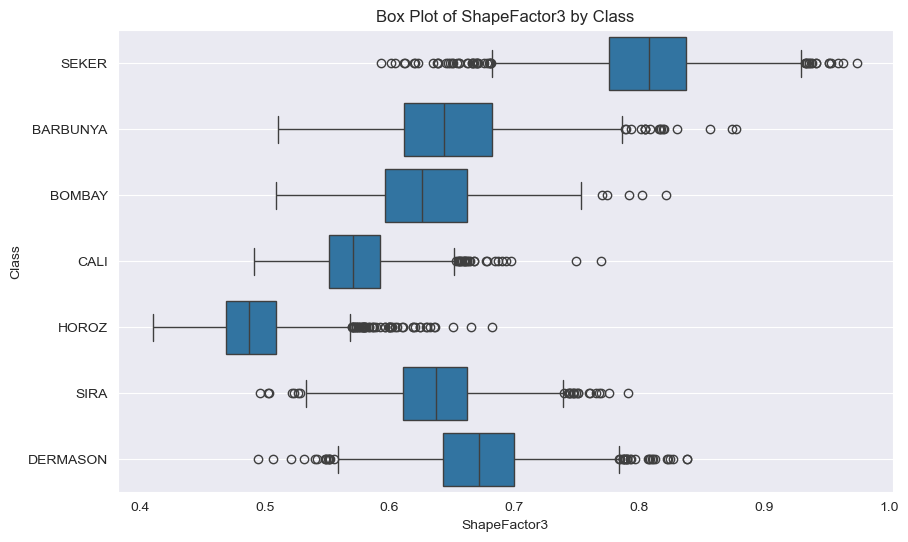

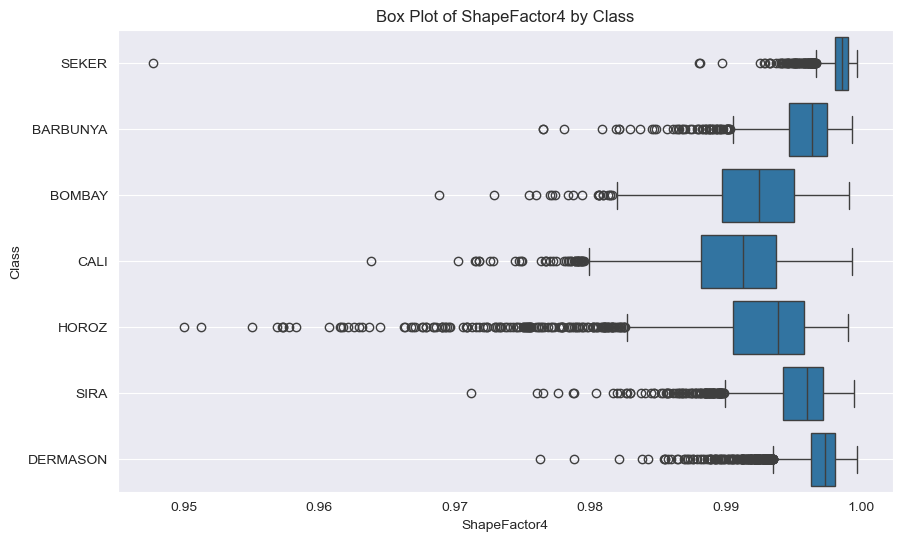

In [33]:
box_plots_per_class(data)
# violin_plots_per_class(data)

In [34]:
def brushed_histograms(df: pd.DataFrame, class_col: str):
    """
    Plots stacked bar histograms for all numerical columns in the DataFrame.
    Each bar is stacked by the 'Class' column, with a different color for each class.
    """
    num_cols = df.select_dtypes(include=[np.number]).columns
    classes = df[class_col].unique()
    colors = sns.color_palette("tab10", len(classes))

    for col in num_cols:
        # Prepare data for stacking
        data_per_class = [df[df[class_col] == cls][col].dropna() for cls in classes]
        plt.figure(figsize=(10, 6))
        plt.hist(
            data_per_class,
            bins=50,
            stacked=True,
            color=colors,
            label=classes,
            edgecolor="black",
        )
        plt.title(f"Stacked Histogram of {col} by {class_col}")
        plt.xlabel(col)
        plt.ylabel("Count")
        plt.legend(title=class_col)
        plt.tight_layout()
        plt.show()


def normalized_stacked_histograms(df: pd.DataFrame, class_col: str, bins=20):
    """
    Plots normalized stacked histograms for all numerical columns in the DataFrame.
    Each bin sums to 100% (relative frequency), and each stack shows the class composition per bin.
    """

    num_cols = df.select_dtypes(include=[np.number]).columns
    classes = df[class_col].unique()
    colors = sns.color_palette("tab10", len(classes))

    for col in num_cols:
        # Compute bin edges
        values = df[col].dropna()
        bin_edges = np.histogram_bin_edges(values, bins=bins)
        bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

        # Compute histogram for each class
        hist_per_class = []
        for cls in classes:
            cls_values = df[df[class_col] == cls][col].dropna()
            hist, _ = np.histogram(cls_values, bins=bin_edges)
            hist_per_class.append(hist)
        hist_per_class = np.array(hist_per_class)  # shape: (n_classes, n_bins)

        # Normalize so each bin sums to 1 (100%)
        bin_sums = hist_per_class.sum(axis=0)
        # Avoid division by zero
        bin_sums[bin_sums == 0] = 1
        hist_norm = hist_per_class / bin_sums

        # Plot
        plt.figure(figsize=(10, 6))
        bottom = np.zeros(hist_norm.shape[1])
        for idx, cls in enumerate(classes):
            plt.bar(
                bin_centers,
                hist_norm[idx],
                width=np.diff(bin_edges),
                bottom=bottom,
                color=colors[idx],
                label=str(cls),
                edgecolor="black",
                align="center",
            )
            bottom += hist_norm[idx]
        plt.title(f"Normalized Stacked Histogram of {col} by {class_col}")
        plt.xlabel(col)
        plt.ylabel("Proportion per bin")
        plt.ylim(0, 1)
        plt.legend(title=class_col)
        plt.tight_layout()
        plt.show()

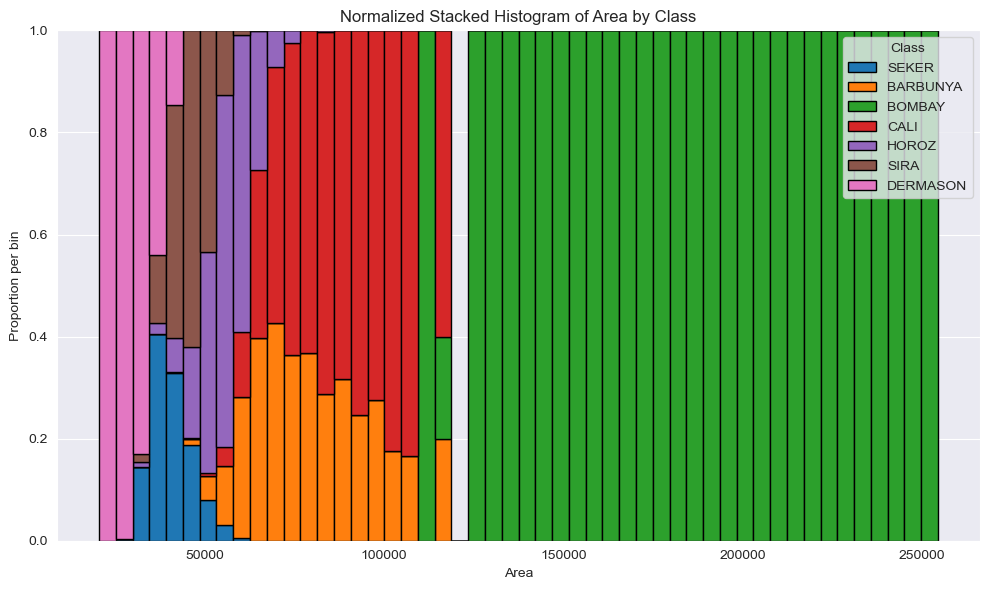

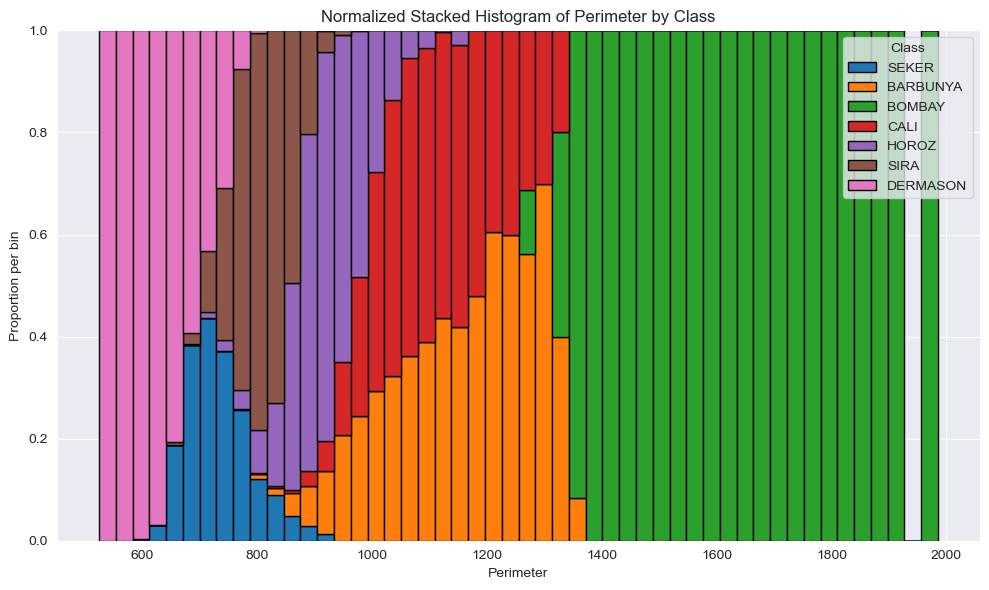

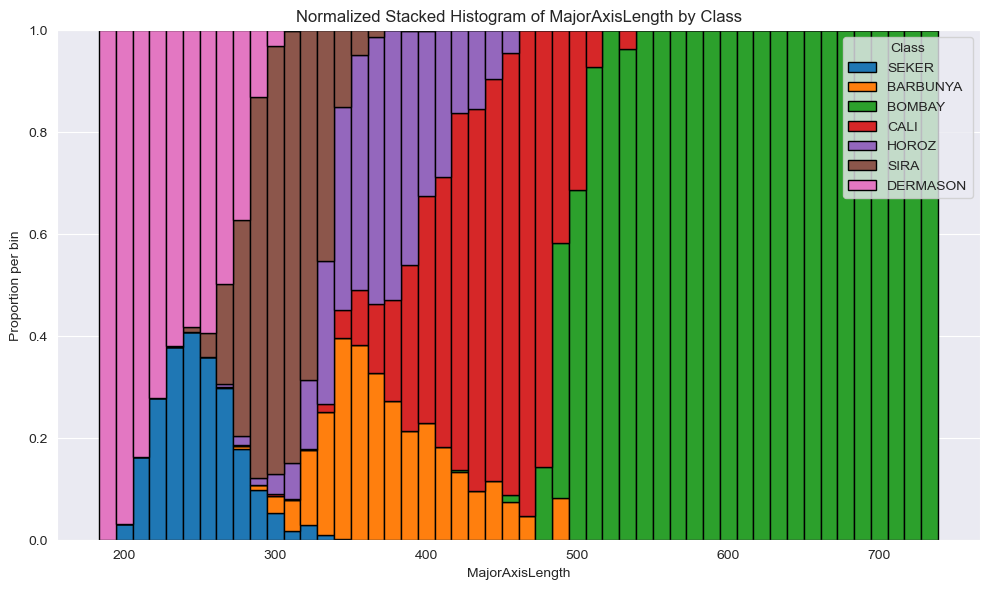

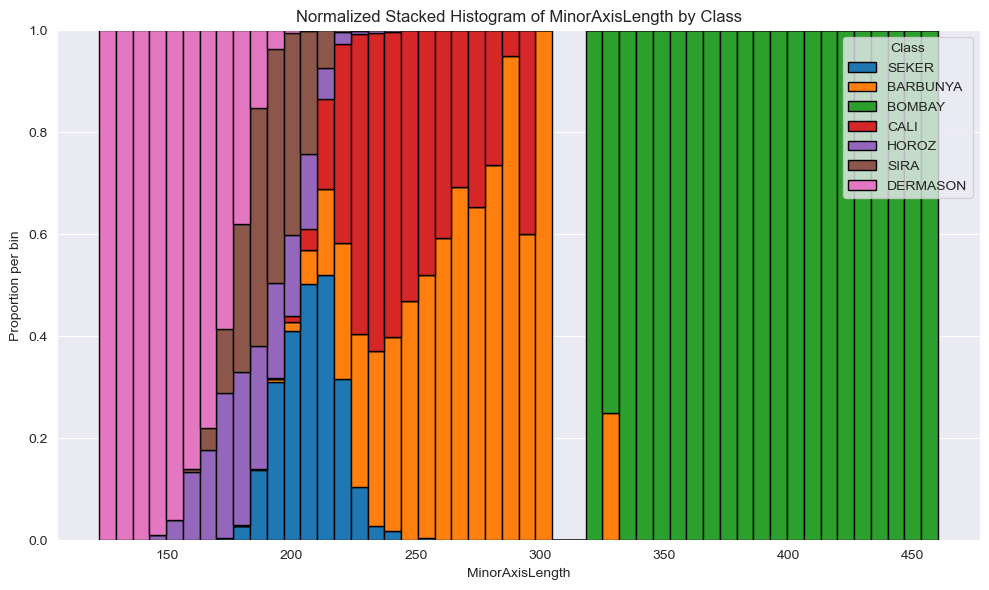

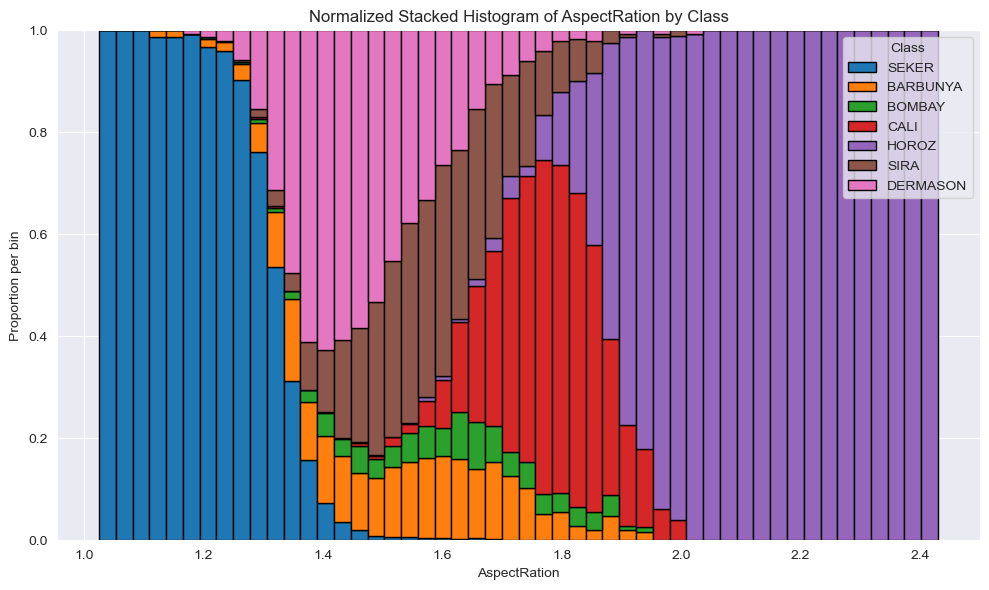

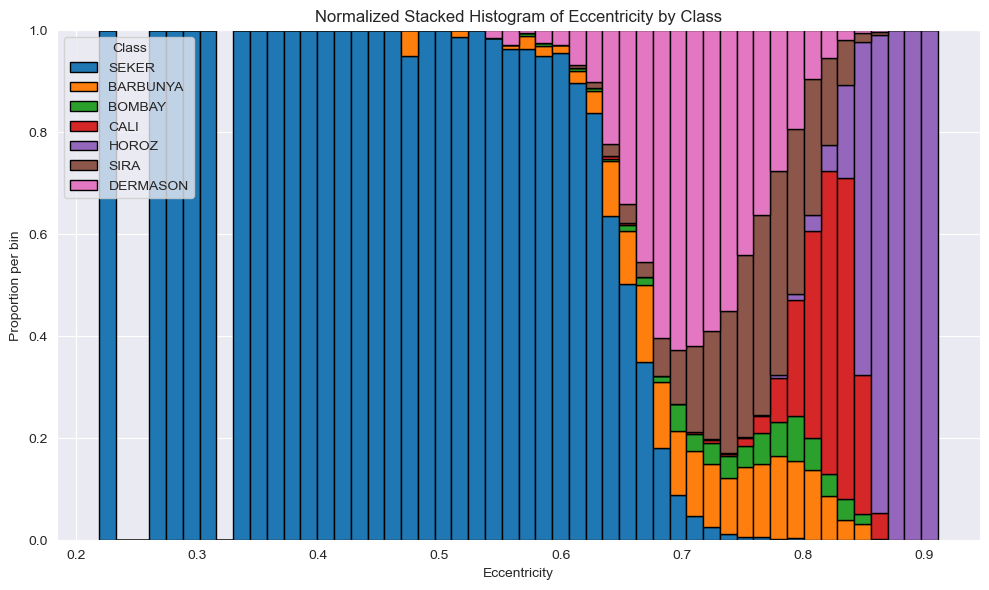

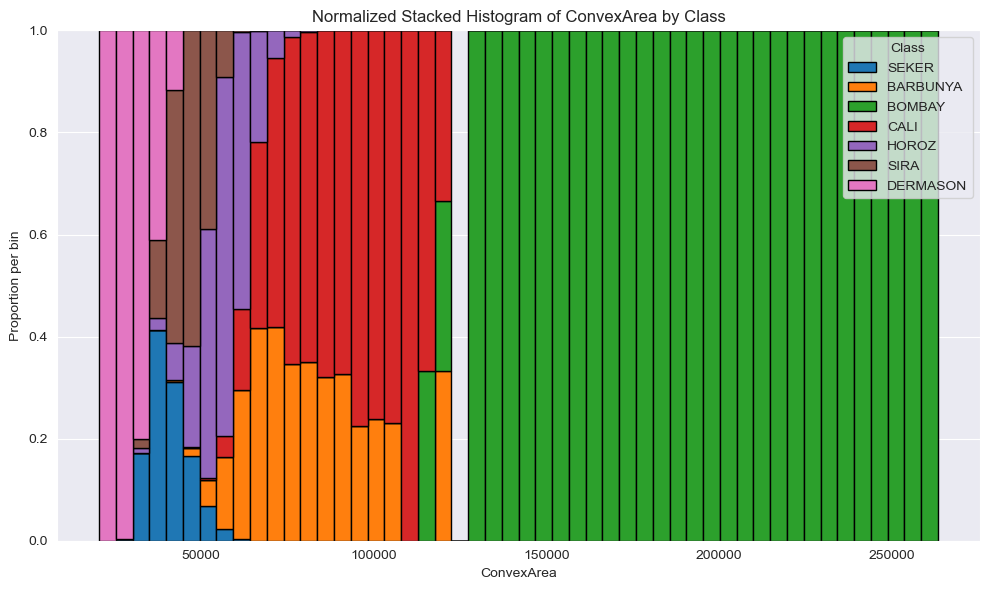

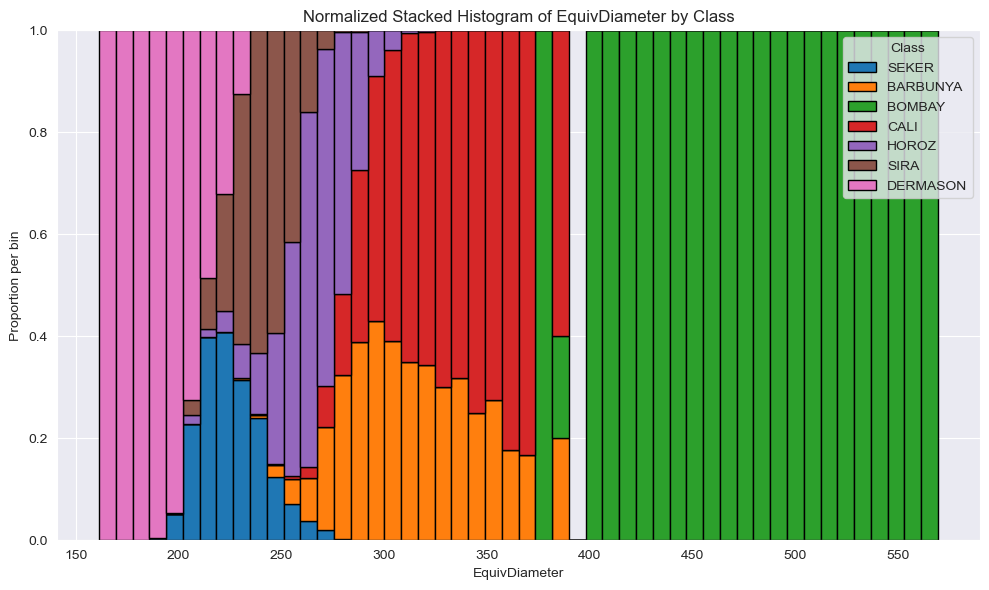

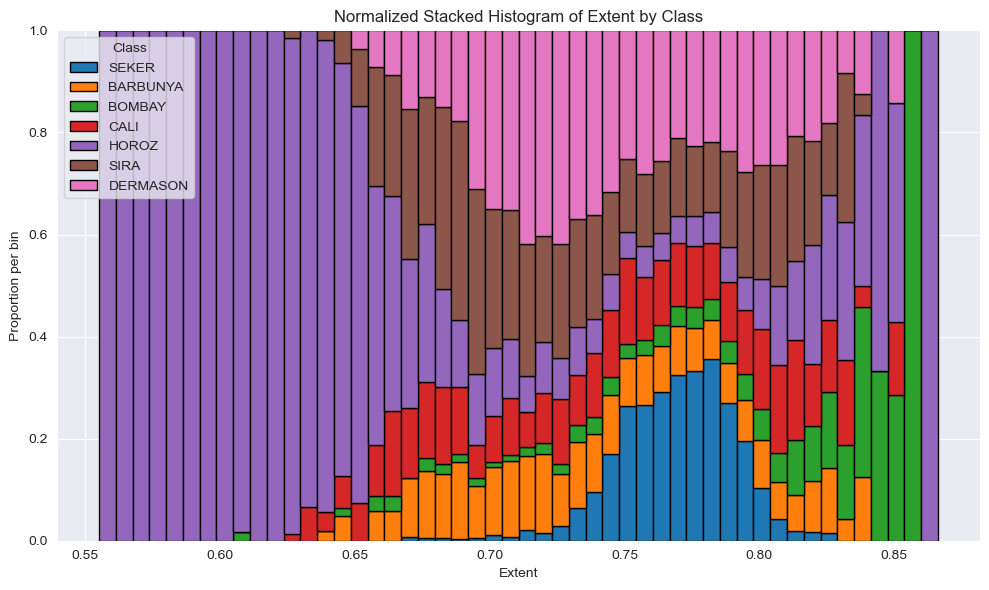

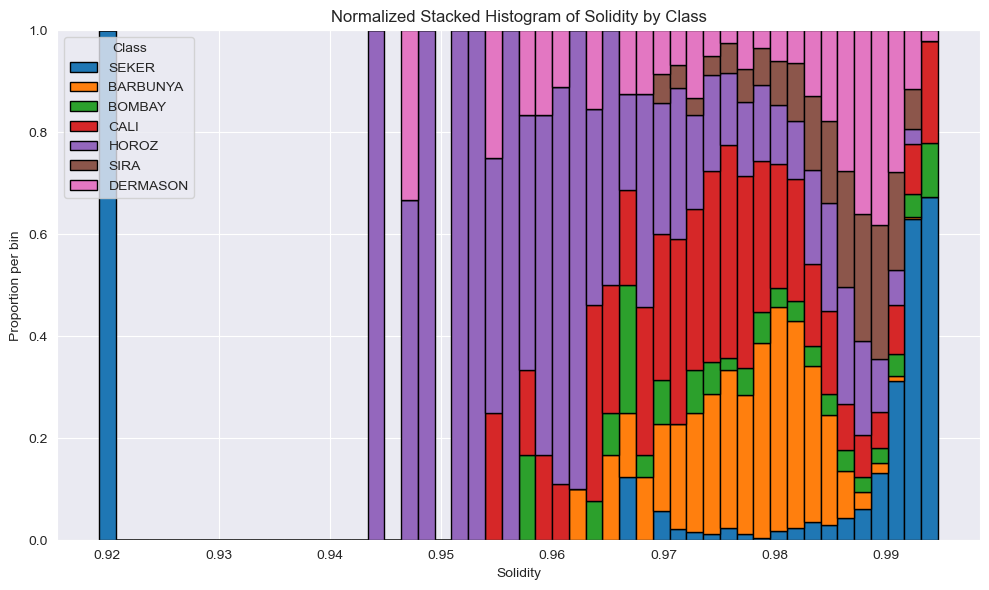

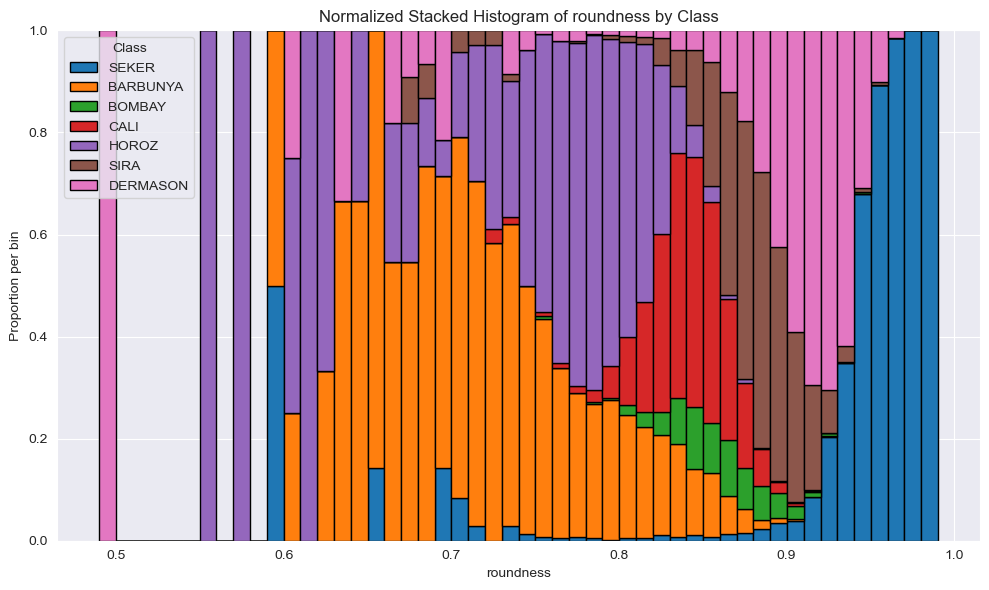

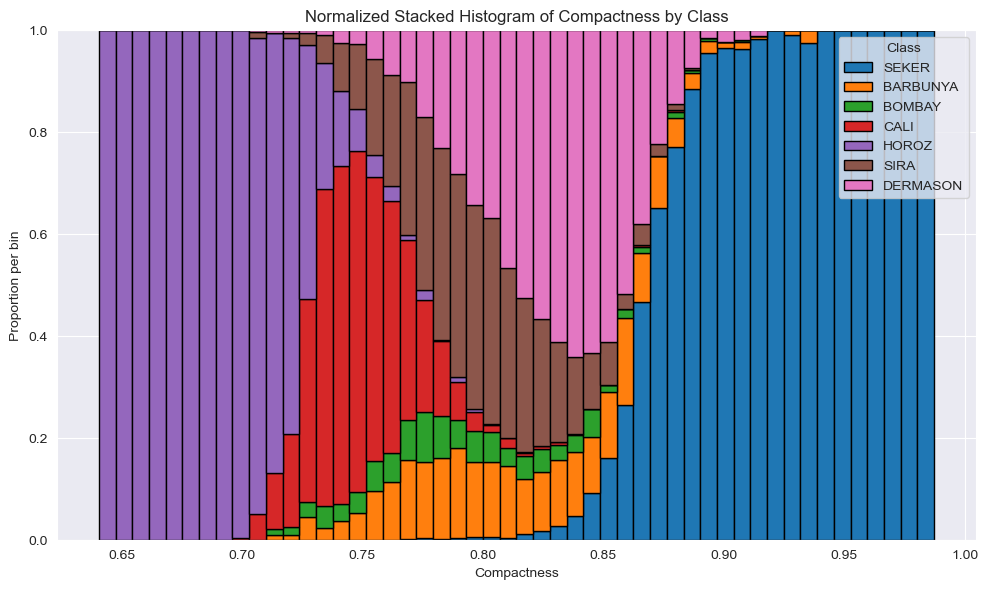

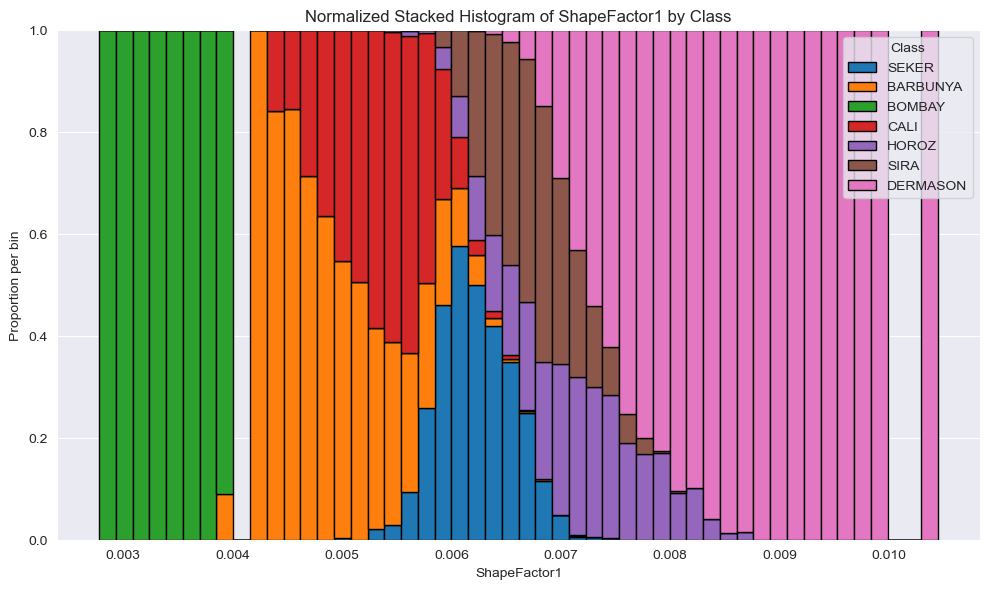

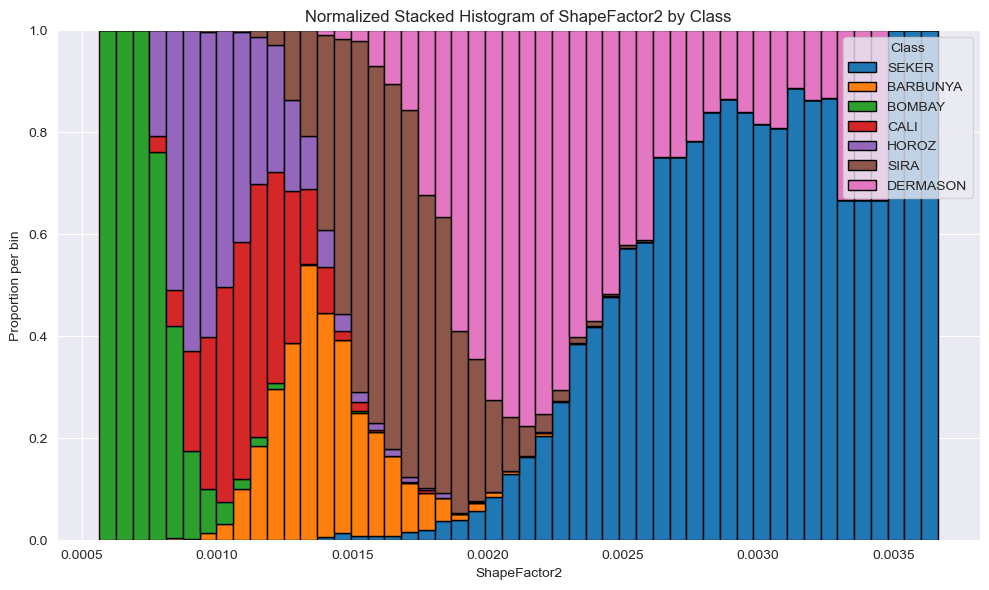

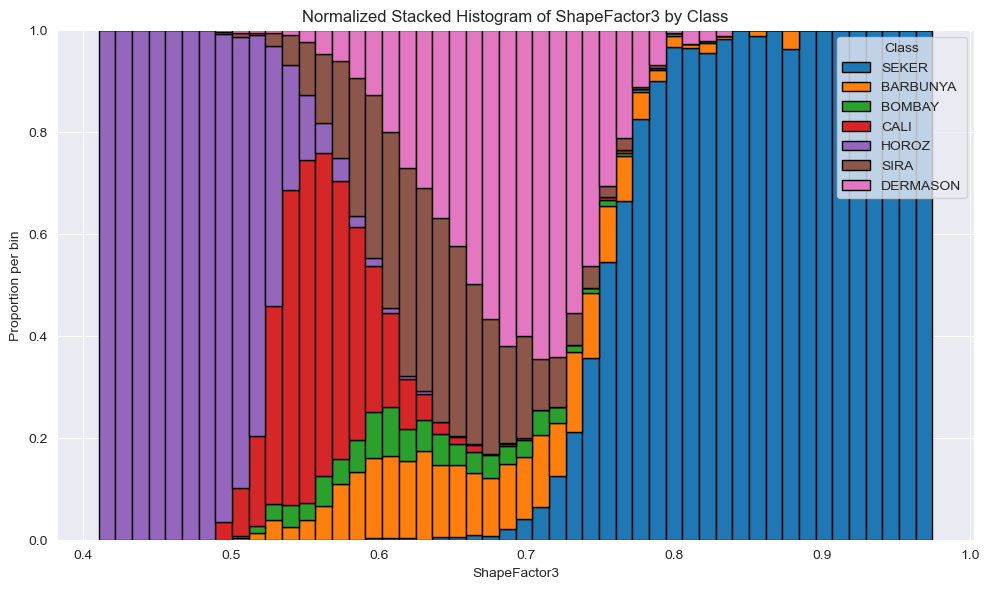

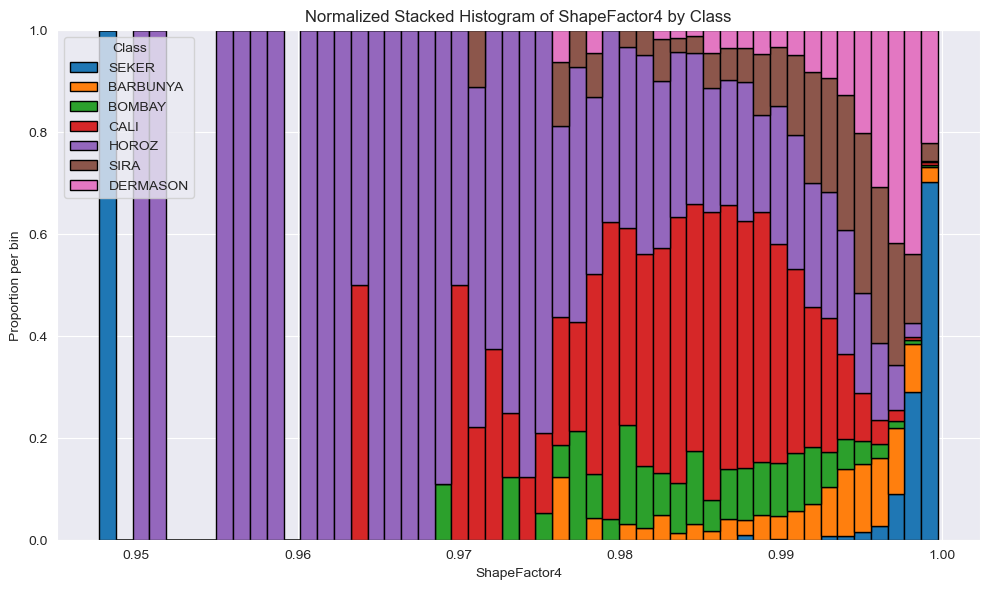

In [35]:
# brushed_histograms(data, class_col="Class")
normalized_stacked_histograms(data, class_col="Class", bins=50)

In [36]:
from matplotlib.patches import Ellipse
from matplotlib.collections import PatchCollection


def spilled_beans(df: pd.DataFrame, x_col: str, y_col: str):
    """
    Fast scatter plot: each bean is an ellipse, colored by class.
    Uses PatchCollection for performance.
    """
    classes = df["Class"].unique()
    colors = sns.color_palette("tab10", len(classes))
    fig, ax = plt.subplots(figsize=(10, 8))

    for idx, cls in enumerate(classes):
        class_data = df[df["Class"] == cls]
        ellipses = [
            Ellipse(
                (row[x_col], row[y_col]),
                width=row["MinorAxisLength"] / 500,
                height=row["MajorAxisLength"] / 500,
                angle=np.random.uniform(0, 360),
            )
            for _, row in class_data.iterrows()
        ]
        if ellipses:
            collection = PatchCollection(
                ellipses,
                facecolor=colors[idx],
                alpha=0.01,
                edgecolor="none",
                label=str(cls),
            )
            ax.add_collection(collection)

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.legend(title="Class")
    plt.tight_layout()
    plt.show()

In [39]:
def check_outliers(df: pd.DataFrame, threshold: float = 2.2) -> dict:
    """
    Check for outliers in numerical columns using Z-score method.
    
    Args:
        df: DataFrame to check for outliers
        threshold: Z-score threshold (default 2.2)
    
    Returns:
        Dictionary containing outlier information per column
    """
    from scipy import stats
    
    outlier_report = {
        "method": "Z-score",
        "threshold": threshold,
        "columns": {},
        "total_outliers": 0,
        "outlier_indices": []
    }
    
    num_cols = df.select_dtypes(include=[np.number]).columns
    
    all_outlier_indices = set()
    
    for col in num_cols:
        z_scores = np.abs(stats.zscore(df[col].dropna()))
        outlier_mask = z_scores > threshold
        outlier_indices = df[col][outlier_mask].index.tolist()
        
        outlier_report["columns"][col] = {
            "outlier_count": len(outlier_indices),
            "outlier_percentage": (len(outlier_indices) / len(df)) * 100,
            "outlier_indices": outlier_indices,
            "mean": float(df[col].mean()),
            "std": float(df[col].std()),
            "min_z_score": float(z_scores.min()),
            "max_z_score": float(z_scores.max())
        }
        
        all_outlier_indices.update(outlier_indices)
    
    outlier_report["total_outliers"] = len(all_outlier_indices)
    outlier_report["outlier_indices"] = list(all_outlier_indices)
    outlier_report["total_rows"] = len(df)
    outlier_report["outlier_percentage"] = (len(all_outlier_indices) / len(df)) * 100
    
    return outlier_report


/var/folders/_9/1s178vp55j1g_748l1wvb1740000gn/T/ipykernel_24089/137719547.py:37: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(title="Class")
/var/folders/_9/1s178vp55j1g_748l1wvb1740000gn/T/ipykernel_24089/137719547.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Class")


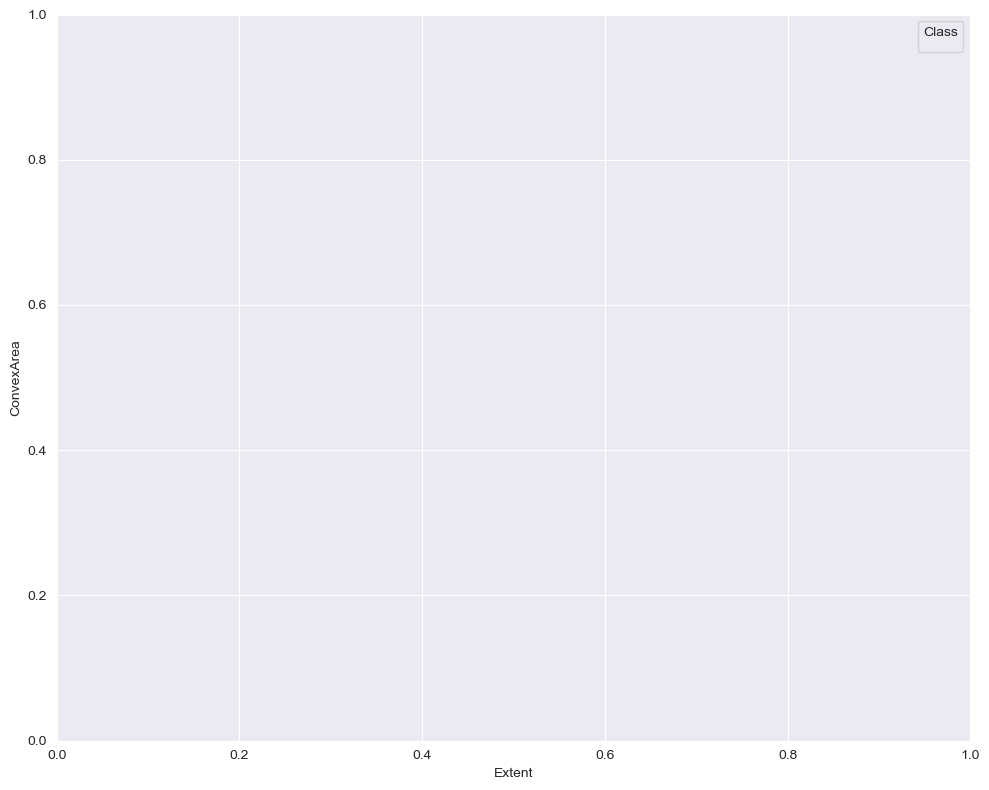

In [37]:
spilled_beans(data, x_col="Extent", y_col="ConvexArea")

In [40]:
check_outliers_code_writer = student_a


start_time_co = now()
outliers_report = check_outliers(data, threshold=2.2)
end_time_co = now()

start_time_ho = now()
print(f"Total outliers found: {outliers_report['total_outliers']} ({outliers_report['outlier_percentage']:.2f}%)")
print(f"Outlier detection method: {outliers_report['method']} with threshold: {outliers_report['threshold']}")
for col, info in outliers_report['columns'].items():
    if info['outlier_count'] > 0:
        print(f"  {col}: {info['outlier_count']} outliers ({info['outlier_percentage']:.2f}%)")
end_time_ho = now()

#############################################
# Documentation
#############################################
# There are three steps involved in this process:
# 1. activity creates a figure, report etc. => in this case a report
# 2. activity inspects the outcome and derives decisions => in this case to remove the outliers that were found
# 3. activity follows up on the decision by changing the data => will be done in the data preparation phase

# 1. Activity: Checking for outliers and creating the report
co_ass_uuid_executor = "86b05086-70a3-4eac-b257-97c9680ceb00"
check_outliers_executor = [
    f":check_outliers prov:qualifiedAssociation :{co_ass_uuid_executor} .",
    f":{co_ass_uuid_executor} prov:agent :{executed_by} .",
    f":{co_ass_uuid_executor} rdf:type prov:Association .",
    f":{co_ass_uuid_executor} prov:hadRole :{code_executor_role} .",
]
engine.insert(check_outliers_executor, prefixes=prefixes)

co_ass_uuid_writer = "6f26e066-050a-42c2-9a65-7b5d8a0f8416"
co_comment = """
Outlier detection was performed using Z-score method with a threshold of 2.2 standard deviations.
This method identifies data points that deviate significantly from the mean. The analysis revealed
outliers across multiple features, with some columns showing higher outlier percentages than others.
Outliers were identified per column and aggregated to determine the total number of affected instances.
"""
check_outliers_activity = [
    ":check_outliers rdf:type prov:Activity .",
    ":check_outliers sc:isPartOf :data_understanding_phase .",
    ":check_outliers rdfs:comment 'Data Understanding' .",
    f':check_outliers rdfs:comment """{co_comment}""" .',
    f':check_outliers prov:startedAtTime "{start_time_co}"^^xsd:dateTime .',
    f':check_outliers prov:endedAtTime "{end_time_co}"^^xsd:dateTime .',
    f":check_outliers prov:qualifiedAssociation :{co_ass_uuid_writer} .",
    f":{co_ass_uuid_writer} prov:agent :{check_outliers_code_writer} .",
    f":{co_ass_uuid_writer} rdf:type prov:Association .",
    f":{co_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    ":check_outliers prov:used :data .",
    ":outlier_report rdf:type prov:Entity .",
    f':outlier_report rdfs:comment """{json.dumps(outliers_report, indent=2)}""" .',
    ":outlier_report prov:wasGeneratedBy :check_outliers .",
]
engine.insert(check_outliers_activity, prefixes=prefixes)

# 2. Activity: Inspecting the report and taking a decision on what to do
ior_ass_uuid_executor = "02c33e8a-5f5f-44ad-bce9-f05e629d9056"
ior_comment = """
After inspecting the report the decision has been made to remove all outliers that were identfied for demonstration purpose3
"""
inspect_outlier_report_executor = student_a
inspect_outlier_report_activity = [
    ":inspect_outlier_report rdf:type prov:Activity .",
    ":inspect_outlier_report sc:isPartOf :data_understanding_phase .",
    ":inspect_outlier_report rdfs:comment 'Data Understanding' .",
    f':inspect_outlier_report rdfs:comment """{ior_comment}""" .',
    f':inspect_outlier_report prov:startedAtTime "{start_time_ho}"^^xsd:dateTime .',
    f':inspect_outlier_report prov:endedAtTime "{end_time_ho}"^^xsd:dateTime .',
    f":inspect_outlier_report prov:qualifiedAssociation :{ior_ass_uuid_executor} .",
    f":{ior_ass_uuid_executor} prov:agent :{inspect_outlier_report_executor} .",
    f":{ior_ass_uuid_executor} rdf:type prov:Association .",
    f":{ior_ass_uuid_executor} prov:hadRole :{code_executor_role} .",
    ":inspect_outlier_report prov:used :outlier_report .",
    ":outlier_decision rdf:type prov:Entity .",
    ':outlier_decision rdfs:comment """Removing outliers with ShapeFactor4 < 0.95 for SEKER class for data quality improvement.""" .',
    ":outlier_decision prov:wasGeneratedBy :inspect_outlier_report .",
]
engine.insert(inspect_outlier_report_activity, prefixes=prefixes)


Total outliers found: 2689 (19.76%)
Outlier detection method: Z-score with threshold: 2.2
  Area: 520 outliers (3.82%)
  Perimeter: 522 outliers (3.84%)
  MajorAxisLength: 500 outliers (3.67%)
  MinorAxisLength: 525 outliers (3.86%)
  AspectRation: 445 outliers (3.27%)
  Eccentricity: 569 outliers (4.18%)
  ConvexArea: 520 outliers (3.82%)
  EquivDiameter: 524 outliers (3.85%)
  Extent: 529 outliers (3.89%)
  Solidity: 491 outliers (3.61%)
  roundness: 254 outliers (1.87%)
  Compactness: 205 outliers (1.51%)
  ShapeFactor1: 590 outliers (4.33%)
  ShapeFactor2: 159 outliers (1.17%)
  ShapeFactor3: 263 outliers (1.93%)
  ShapeFactor4: 491 outliers (3.61%)


In [41]:
def check_statistical_properties(data: pd.DataFrame) -> dict:
    """
    Check statistical properties of the dataset including correlations.
    
    Args:
        data: DataFrame to analyze
    
    Returns:
        Dictionary containing statistical properties
    """
    report = {
        "shape": data.shape,
        "numerical_columns": [],
        "categorical_columns": [],
        "descriptive_stats": {},
        "correlations": {},
        "skewness": {},
        "kurtosis": {}
    }
    
    num_cols = data.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = data.select_dtypes(include=['object']).columns.tolist()
    
    report["numerical_columns"] = num_cols
    report["categorical_columns"] = cat_cols
    
    # Descriptive statistics
    desc_stats = data[num_cols].describe()
    report["descriptive_stats"] = desc_stats.to_dict()
    
    # Correlation matrix
    if len(num_cols) > 1:
        corr_matrix = data[num_cols].corr()
        report["correlations"] = corr_matrix.to_dict()
    
    # Skewness and Kurtosis
    for col in num_cols:
        report["skewness"][col] = float(data[col].skew())
        report["kurtosis"][col] = float(data[col].kurtosis())
    
    return report

In [ ]:
statistical_properties_code_writer = student_a

start_time_sd = now()
statistical_properties_report = check_statistical_properties(data)
end_time_sd = now()

print(f"Dataset shape: {statistical_properties_report['shape']}")
print(f"Numerical columns: {len(statistical_properties_report['numerical_columns'])}")
print(f"Categorical columns: {len(statistical_properties_report['categorical_columns'])}")
print(f"\nSkewness summary:")
for col, skew_val in statistical_properties_report['skewness'].items():
    if abs(skew_val) > 1:
        print(f"  {col}: {skew_val:.3f} (highly skewed)")

# 1. Activity: Checking statistical properties of the dataset
csd_ass_uuid_executor = "a3f8b2c1-9d4e-4f5a-8b7c-1e2d3f4a5b6c"
check_statistical_properties_executor = [
    f":check_statistical_properties prov:qualifiedAssociation :{csd_ass_uuid_executor} .",
    f":{csd_ass_uuid_executor} prov:agent :{executed_by} .",
    f":{csd_ass_uuid_executor} rdf:type prov:Association .",
    f":{csd_ass_uuid_executor} prov:hadRole :{code_executor_role} .",
]
engine.insert(check_statistical_properties_executor, prefixes=prefixes)

csd_ass_uuid_writer = "b4e9c3d2-0e5f-5a6b-9c8d-2f3e4a5b6c7d"
sd_comment = """
Statistical properties analysis was performed on the dataset including:
- Descriptive statistics (mean, std, min, max, quartiles) for all numerical features
- Correlation matrix to identify relationships between features
- Skewness and kurtosis measures to assess data distribution shapes
The analysis revealed several features with high skewness, indicating non-normal distributions.
Strong correlations were found between related morphological features (e.g., Area and ConvexArea).
"""
statistical_properties_activity = [
    ":stat_properties rdf:type prov:Activity .",
    ":stat_properties sc:isPartOf :data_understanding_phase .",
    ":stat_properties rdfs:comment 'Data Understanding' .",
    f':stat_properties rdfs:comment """{sd_comment}""" .',
    f':stat_properties prov:startedAtTime "{start_time_sd}"^^xsd:dateTime .',
    f':stat_properties prov:endedAtTime "{end_time_sd}"^^xsd:dateTime .',
    f":stat_properties prov:qualifiedAssociation :{csd_ass_uuid_writer} .",
    f":{csd_ass_uuid_writer} prov:agent :{statistical_properties_code_writer} .",
    f":{csd_ass_uuid_writer} rdf:type prov:Association .",
    f":{csd_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    ":stat_properties prov:used :data .",
    ":statistical_report rdf:type prov:Entity .",
    f':statistical_report rdfs:comment """Statistical properties analysis report including descriptive statistics, correlations, skewness, and kurtosis.""" .',
    ":statistical_report prov:wasGeneratedBy :stat_properties .",
]

engine.insert(statistical_properties_activity, prefixes=prefixes)

## Data Preparation

In [ ]:
## Each Activity that follows is part of the Data Preparation Phase

data_preparation_phase_executor = [
    ":data_preparation_phase rdf:type prov:Activity .",
    ':data_preparation_phase rdfs:label "Data Preparation Phase" .',
]
engine.insert(data_preparation_phase_executor, prefixes=prefixes)

In [ ]:
#############################################
# Documentation 2g: Data Preparation Actions
#############################################

prep_actions_code_writer = student_a

prep_actions_comment = """
Actions required in data preparation based on the analysis:

1. **Outlier Removal**:
   - Remove instances identified as outliers using Z-score method (threshold 2.2)
   - Specifically remove SEKER class instances with ShapeFactor4 < 0.95
   - This will improve data quality and model performance

2. **Feature Scaling**:
   - Apply scaling to features with large value ranges (Area, Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea, EquivDiameter)
   - Use StandardScaler or MinMaxScaler to normalize these features
   - Important: Apply scaling AFTER train/test split to prevent data leakage

3. **Class Encoding**:
   - Convert categorical Class column to numerical format suitable for classification
   - Use one-hot encoding or label encoding depending on the chosen algorithm
   - One-hot encoding is preferred for algorithms that don't assume ordinal relationships

4. **Train/Validation/Test Split**:
   - Use stratified splitting to maintain class distribution across all subsets
   - Recommended split: 60% training, 20% validation, 20% test
   - Set random seed for reproducibility

5. **Feature Selection** (Optional):
   - Consider removing highly correlated features to reduce redundancy
   - Use correlation analysis to identify feature pairs with correlation > 0.9
   - Keep the feature that is more interpretable or has stronger predictive power

6. **Data Validation**:
   - Verify no missing values remain after preprocessing
   - Check for any remaining implausible values
   - Ensure all numerical features are in expected ranges

7. **Documentation**:
   - Document all preprocessing steps in the knowledge graph
   - Record transformation parameters (e.g., scaler coefficients) for reproducibility
   - Create provenance links between original and preprocessed datasets
"""

prep_actions_ass_uuid_writer = "e7b2f6a5-3b8c-8d9e-2f1a-5c6d7e8f9a0b"
prep_actions_activity = [
    ":prep_actions_planning rdf:type prov:Activity .",
    ":prep_actions_planning sc:isPartOf :data_understanding_phase .",
    ":prep_actions_planning rdfs:comment 'Data Understanding' .",
    f':prep_actions_planning rdfs:comment """{prep_actions_comment}""" .',
    f":prep_actions_planning prov:qualifiedAssociation :{prep_actions_ass_uuid_writer} .",
    f":{prep_actions_ass_uuid_writer} prov:agent :{prep_actions_code_writer} .",
    f":{prep_actions_ass_uuid_writer} rdf:type prov:Association .",
    f":{prep_actions_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    ":prep_actions_planning prov:used :data .",
    ":prep_actions_planning prov:used :outlier_report .",
    ":prep_actions_planning prov:used :statistical_report .",
    ":prep_actions_report rdf:type prov:Entity .",
    ':prep_actions_report rdfs:label "2g Data Preparation Actions" .',
    ":prep_actions_report prov:wasGeneratedBy :prep_actions_planning .",
]
engine.insert(prep_actions_activity, prefixes=prefixes)


In [21]:
def handle_outliers(df: pd.DataFrame, outliers_report: dict) -> pd.DataFrame:
    condition = (df["Class"] == "SEKER") & (df["ShapeFactor4"] < 0.95)
    df = df[~condition].reset_index(drop=True)
    return df

In [22]:
data = handle_outliers(data, None)

In [ ]:
handle_outliers_code_writer = student_b


start_time_td = now()
data = handle_outliers(data, None)
end_time_td = now()

#############################################
# Documentation
#############################################
# This is the continuation of the example from the Data Understanding phase above.
# There are three steps involved in this process:
# 1. activity creates a figure, report etc. => already done in data understanding phase
# 2. activity inspects the outcome and derives decisions => already done in data understanding phase
# 3. activity follows up on the decision by changing the data => in this case by removing the the outliers that were found

ro_ass_uuid_executor = "7d6cecd2-0cc9-4094-a10b-4a601b76463b"
handle_outliers_executor = [
    f":handle_outliers prov:qualifiedAssociation :{ro_ass_uuid_executor} .",
    f":{ro_ass_uuid_executor} prov:agent :{executed_by} .",
    f":{ro_ass_uuid_executor} rdf:type prov:Association .",
    f":{ro_ass_uuid_executor} prov:hadRole :{code_executor_role} .",
]
engine.insert(handle_outliers_executor, prefixes=prefixes)

td_ass_uuid_writer = "e75185e3-0328-49ba-99da-9003d45b0b9a"
td_comment = """
Removed all instances of the SEKER class where `ShapeFactor4` was below 0.95.
"""
handle_outliers_activity = [
    ":handle_outliers rdf:type prov:Activity .",
    ":handle_outliers sc:isPartOf :data_preparation_phase .",
    ":handle_outliers rdfs:comment 'Data Preparation' .",
    f':handle_outliers rdfs:comment """{td_comment}""" .',
    f':handle_outliers prov:startedAtTime "{start_time_td}"^^xsd:dateTime .',
    f':handle_outliers prov:endedAtTime "{end_time_td}"^^xsd:dateTime .',
    f":handle_outliers prov:qualifiedAssociation :{td_ass_uuid_writer} .",
    f":{td_ass_uuid_writer} prov:agent :{handle_outliers_code_writer} .",
    f":{td_ass_uuid_writer} rdf:type prov:Association .",
    f":{td_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    ":handle_outliers prov:used :data .",
    ":handle_outliers prov:used :outlier_decision .",
    ":cleaned_data rdf:type prov:Entity .",
    ":cleaned_data prov:wasGeneratedBy :handle_outliers .",
    ":cleaned_data prov:wasDerivedFrom :data .",
]
engine.insert(handle_outliers_activity, prefixes=prefixes)

**Continue with other tasks of the Data Preparation phase such as binning, scaling etc...**

In [ ]:
def one_hot_encoding(df: pd.DataFrame) -> pd.DataFrame:
    """
    The class has seven values. We transform the 'Class' column into one-hot encoded columns.
    The original class column is dropped.
    """
    dfc = df.copy()
    dfc = pd.get_dummies(dfc, columns=["Class"], prefix="Class")
    return dfc


def scaling(df: pd.DataFrame, strategy: str) -> pd.DataFrame:
    """
    Scaling will only be applied to the columns
    - Area
    - Perimeter
    - MajorAxisLength
    - MinorAxisLength
    - ConvexArea
    - EquivDiameter
    """
    dfc = df.copy()
    cols_to_scale = [
        "Area",
        "Perimeter",
        "MajorAxisLength",
        "MinorAxisLength",
        "ConvexArea",
        "EquivDiameter",
    ]
    if strategy == "min-max":
        scaler = MinMaxScaler()
    elif strategy == "standard":
        scaler = StandardScaler()
    else:
        raise ValueError(f"Unknown scaling strategy: {strategy}")
    dfc[cols_to_scale] = scaler.fit_transform(dfc[cols_to_scale])
    return dfc, scaler

In [ ]:
data_ohe = one_hot_encoding(data)

In [ ]:
# Your final transformed dataset should also be documented appropriately using Croissant, SI, etc.

prepared_data_triples = [
    ":prepared_data rdf:type prov:Entity .",
    ":prepared_data prov:wasDerivedFrom :cleaned_data .",
    ":prepared_data rdf:type sc:Dataset .",
    # ....
    ":prepared_data rdf:type sc:Dataset .",
    ":prepared_data sc:name 'Prepared Dry Bean Dataset' .",
    ":prepared_data sc:description 'Morphological features describing seven dry bean classes.' .",
    ":prepared_data sc:licence 'https://creativecommons.org/licenses/by/4.0/legalcode' .",
    # Continue with further information about the distribution...
    ":prepared_recordset rdf:type cr:RecordSet .",
    ":prepared_recordset sc:name 'Table of prepared dry bean data' .",
    ":prepared_recordset cr:source :dry_bean_arff .",
    ":prepared_data cr:recordSet :prepared_recordset .",
    ###
    ":prepared_recordset cr:field :field_class_seker .",
    ":field_class_seker rdf:type cr:Field .",
    ":field_class_seker sc:name 'Class_SEKER' .",
    ":field_class_seker sc:description 'Seker dry bean variety' .",
    ":field_class_seker cr:dataType xsd:boolean .",
    #
    ":prepared_recordset cr:field :field_class_barbunya .",
    ":field_class_barbunya rdf:type cr:Field .",
    ":field_class_barbunya sc:name 'Class_BARBUNYA' .",
    ":field_class_barbunya sc:description 'Barbunya dry bean variety' .",
    ":field_class_barbunya cr:dataType xsd:boolean .",
    #
    ":prepared_recordset cr:field :field_class_bombay .",
    ":field_class_bombay rdf:type cr:Field .",
    ":field_class_bombay sc:name 'Class_BOMBAY' .",
    ":field_class_bombay sc:description 'Bombay dry bean variety' .",
    ":field_class_bombay cr:dataType xsd:boolean .",
    #
    ":prepared_recordset cr:field :field_class_cali .",
    ":field_class_cali rdf:type cr:Field .",
    ":field_class_cali sc:name 'Class_CALI' .",
    ":field_class_cali sc:description 'Cali dry bean variety' .",
    ":field_class_cali cr:dataType xsd:boolean .",
    #
    ":prepared_recordset cr:field :field_class_dermosan .",
    ":field_class_dermosan rdf:type cr:Field .",
    ":field_class_dermosan sc:name 'Class_DERMOSAN' .",
    ":field_class_dermosan sc:description 'Dermosan dry bean variety' .",
    ":field_class_dermosan cr:dataType xsd:boolean .",
    #
    ":prepared_recordset cr:field :field_class_horoz .",
    ":field_class_horoz rdf:type cr:Field .",
    ":field_class_horoz sc:name 'Class_HOROZ' .",
    ":field_class_horoz sc:description 'Horoz dry bean variety' .",
    ":field_class_horoz cr:dataType xsd:boolean .",
    #
    ":prepared_recordset cr:field :field_class_sira .",
    ":field_class_sira rdf:type cr:Field .",
    ":field_class_sira sc:name 'Class_SIRA' .",
    ":field_class_sira sc:description 'Sira dry bean variety' .",
    ":field_class_sira cr:dataType xsd:boolean .",
]
engine.insert(prepared_data_triples, prefixes=prefixes)

In [ ]:
other_preproc_steps_uuid_executor = ""  # TODO

other_preproc_steps_executor = [
    f":other_preproc_steps prov:qualifiedAssociation :{other_preproc_steps_uuid_executor} .",
    f":{other_preproc_steps_uuid_executor} prov:agent :{executed_by} .",
    f":{other_preproc_steps_uuid_executor} rdf:type prov:Association .",
    f":{other_preproc_steps_uuid_executor} prov:hadRole :{code_executor_role} .",
]

other_prepro_comment = """
We have considered scaling some of the features with highest mean, like the area or the perimeter. However, we consider this scaling (done or not) cannot be performed before train/validation/test splitting due to possible data leakage. Test set instances should never influence by how much the train and validation sets are scaled.

Adding more derived attributes does not seem truly necessary, as many of the already exisiting features are already derivations of other measures. So much so, that the four last attributes are simply called "ShapeFactorX".

Additional information that could be interesting to add into the dataset is some form of color information. According to the original paper where this dataset is presented, all dry bean images were first converted into black and white images for feature extraction. At the same time, we know that one of the dry bean varieties, the Barbunya, possesses certain colourful characteristics, that are lost during b/w conversion.
"""

other_preprocessing_steps_activity = [
    ":other_preproc_steps rdf:type prov:Activity .",
    ":other_preproc_steps sc:isPartOf :data_preparation_phase .",
    f":other_preproc_steps rdfs:comment '{other_prepro_comment}' .",
]

engine.insert(other_preprocessing_steps_activity, prefixes=prefixes)

## Modeling

In [ ]:
## Each Activity that follows is part of the Modeling Phase

modeling_phase_executor = [
    ":modeling_phase rdf:type prov:Activity .",
    ':modeling rdfs:label "Modeling Phase" .',
]
engine.insert(modeling_phase_executor, prefixes=prefixes)


In [ ]:
model_data_code_writer = student_a

#############################################
# Documentation 4a
#############################################

dma_ass_uuid_writer = "097ea442-7b97-464d-926f-ad0a0882d142"
dma_comment = """
Suitable data mining algorithms for multiclass classification of dry beans:

1. **Random Forest**: 
   - Handles non-linear relationships and feature interactions well
   - Provides feature importance scores for interpretability
   - Robust to outliers and requires minimal preprocessing
   - Good performance on tabular data with mixed feature types
   - Selected as primary algorithm due to these advantages

2. **Support Vector Machine (SVM)**:
   - Effective for high-dimensional data
   - Can handle non-linear relationships with kernel functions
   - However, less interpretable and slower on large datasets

3. **Gradient Boosting (XGBoost/LightGBM)**:
   - Often achieves highest accuracy
   - Good at capturing complex patterns
   - More computationally intensive and requires more hyperparameter tuning

4. **Neural Networks**:
   - Can model complex non-linear relationships
   - Requires more data and computational resources
   - Less interpretable than tree-based methods

**Selection Justification**: Random Forest is selected as the primary algorithm because:
- It provides excellent performance for multiclass classification
- Feature importance scores help identify the 5 most important features (business requirement)
- Robust to outliers and requires minimal data preprocessing
- Fast training and prediction times
- Good interpretability through feature importance
- Works well with the dataset size (13,611 instances)
"""

identify_data_mining_algorithm_activity = [
    ":define_algorithm rdf:type prov:Activity .",
    ":define_algorithm sc:isPartOf :modeling_phase .",
    f':define_algorithm rdfs:comment """{dma_comment}""" .',
    f":define_algorithm prov:qualifiedAssociation :{dma_ass_uuid_writer} .",
    f":{dma_ass_uuid_writer} prov:agent :{model_data_code_writer} .",
    f":{dma_ass_uuid_writer} rdf:type prov:Association .",
    f":{dma_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    # example algorithm definition
    ":random_forest_algorithm rdf:type mls:Algorithm .",
    ':random_forest_algorithm rdfs:label "Random Forest Algorithm" .',
    # example implementation
    ":random_forrest_classifier_implementation rdf:type mls:Implementation .",
    ':random_forrest_classifier_implementation rdfs:label "Scikit-learn RandomForestClassifier" .',
    ":random_forrest_classifier_implementation mls:implements :random_forest_algorithm .",
    ":random_forrest_classifier_implementation prov:wasGeneratedBy :define_algorithm .",
    # you can also define your Evaluation Measures here
    # example evaluation
    ":r2_score_measure rdf:type mls:EvaluationMeasure .",
    ':r2_score_measure rdfs:label "R-squared Score" .',
    ':r2_score_measure rdfs:comment "xxx" .',
    ":r2_score_measure prov:wasGeneratedBy :define_algorithm .",
]
engine.insert(identify_data_mining_algorithm_activity, prefixes=prefixes)

In [ ]:
#############################################
# Documentation 4b
#############################################

hp_ass_uuid_writer = "0635254c-37a7-4037-97f2-4e8991aef199"
hp_comment = """
Hyperparameters available for Random Forest tuning:

1. **n_estimators** (Most Relevant for Tuning):
   - Number of trees in the forest
   - Range: 50-500 (test: 50, 100, 200, 300, 500)
   - Impact: More trees improve performance but increase computation time
   - Selected for tuning as it has the highest impact on model performance
   - Step-width: Incremental increases to find optimal balance

2. **max_depth**:
   - Maximum depth of trees
   - Range: 5-30 (test: 5, 10, 15, 20, None)
   - Impact: Prevents overfitting, affects model complexity
   - Will tune with moderate step-width

3. **min_samples_split**:
   - Minimum samples required to split a node
   - Range: 2-20 (test: 2, 5, 10, 20)
   - Impact: Controls tree growth, prevents overfitting

4. **min_samples_leaf**:
   - Minimum samples required in a leaf node
   - Range: 1-10 (test: 1, 2, 4, 8)
   - Impact: Smooths predictions, prevents overfitting

5. **max_features**:
   - Number of features to consider for best split
   - Options: 'sqrt', 'log2', None (test all)
   - Impact: Reduces overfitting, affects feature importance

**Tuning Strategy**: Grid search will be performed focusing primarily on n_estimators
with secondary tuning of max_depth and min_samples_split. The tuning process will
evaluate performance on validation set to identify optimal hyperparameter combination.
"""
identify_hp_activity = [
    ":identify_hyperparameters rdf:type prov:Activity .",
    ":identify_hyperparameters sc:isPartOf :modeling_phase .",
    f':identify_hyperparameters rdfs:comment """{hp_comment}""" .',
    f":identify_hyperparameters prov:qualifiedAssociation :{hp_ass_uuid_writer} .",
    f":{hp_ass_uuid_writer} prov:agent :{model_data_code_writer} .",
    f":{hp_ass_uuid_writer} rdf:type prov:Association .",
    f":{hp_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    # example parameter
    ":hp_learning_rate rdf:type mls:HyperParameter .",
    ':hp_learning_rate rdfs:label "Learning Rate" .',
    ':hp_learning_rate rdfs:comment "..." .',
    ":random_forrest_classifier_implementation mls:hasHyperParameter :hp_learning_rate .",
    ":hp_learning_rate prov:wasGeneratedBy :identify_hyperparameters .",
    # continue with your identified hyperparameters
]
engine.insert(identify_hp_activity, prefixes=prefixes)

In [ ]:
def split_data(df: pd.DataFrame):
    # do something
    return "train_set", "validation_set", "test_set"


#############################################
# Documentation 4c
#############################################

### Define Train/Validation/Test splits
split_ass_uuid_writer = "2a79da72-5b87-4d91-b7ab-e52e467edc26"
split_comment = """
...
"""
## Use your prepared dataset
input_dataset = ":prepared_data"

define_split_activity = [
    ":define_data_split rdf:type prov:Activity .",
    ":define_data_split sc:isPartOf :modeling_phase .",
    ':define_data_split rdfs:comment "Train/Validation/Test Split Definition" .',
    f':define_data_split rdfs:comment """{split_comment}""" .',
    f":define_data_split prov:qualifiedAssociation :{split_ass_uuid_writer} .",
    f":{split_ass_uuid_writer} prov:agent :{model_data_code_writer} .",
    f":{split_ass_uuid_writer} rdf:type prov:Association .",
    f":{split_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    f":define_data_split prov:used {input_dataset} .",
    # Training Set
    ":training_set rdf:type sc:Dataset .",
    ':training_set rdfs:label "Training Set" .',
    ":training_set prov:wasGeneratedBy :define_data_split .",
    f":training_set prov:wasDerivedFrom {input_dataset} .",
    ':training_set rdfs:comment "Contains xx samples" .',
    # Validation Set
    ":validation_set rdf:type sc:Dataset .",
    ':validation_set rdfs:label "Validation Set" .',
    ":validation_set prov:wasGeneratedBy :define_data_split .",
    f":validation_set prov:wasDerivedFrom {input_dataset} .",
    ':validation_set rdfs:comment "Contains xx samples" .',
    # Test Set
    ":test_set rdf:type sc:Dataset .",
    ':test_set rdfs:label "Test Set" .',
    ":test_set prov:wasGeneratedBy :define_data_split .",
    f":test_set prov:wasDerivedFrom {input_dataset} .",
    ':test_set rdfs:comment "Contains xx samples" .',
]
engine.insert(define_split_activity, prefixes=prefixes)

In [ ]:
def train_and_finetune_model(training_set, validation_set):
    # do something here

    # Try to automate as much documentation work as possible.
    # Define your training runs with their respective hyperparameter settings, etc.
    # Document each time a training run, model, its hp_settings, evaluations, ...
    # Create performance figures/graphs

    return "Find most suitable model"


start_time_tafm = now()
# train_and_finetune_model()
end_time_tafm = now()


#############################################
# Documentation 4d & e & f
#############################################

tafm_ass_uuid_writer = "d08c8893-379a-4af5-aaaf-e73dab042329"
tafm_comment = """
...
"""

# EXAMPLE output from your training
training_run1 = "run_1"
model_run1 = "model_run1"
hp1_setting_run1 = "hp_setting_run1"
eval_train_run1 = "metric_train_run1"
eval_validation_run1 = "metric_validation_run1"


train_model_activity = [
    # Activity
    ":train_and_finetune_model rdf:type prov:Activity .",
    ":train_and_finetune_model sc:isPartOf :modeling_phase .",
    f':train_and_finetune_model rdfs:comment """{tafm_comment}""" .',
    f':train_and_finetune_model prov:startedAtTime "{start_time_tafm}"^^xsd:dateTime .',
    f':train_and_finetune_model prov:endedAtTime "{end_time_tafm}"^^xsd:dateTime .',
    f":train_and_finetune_model prov:qualifiedAssociation :{tafm_ass_uuid_writer} .",
    f":{tafm_ass_uuid_writer} prov:agent :{model_data_code_writer} .",
    f":{tafm_ass_uuid_writer} rdf:type prov:Association .",
    f":{tafm_ass_uuid_writer} prov:hadRole :{code_writer_role} .",
    ########################################
    # ONE model run - automate everything below!
    # Parameter settings
    f":{hp1_setting_run1} rdf:type mls:HyperParameterSetting .",
    f":{hp1_setting_run1} mls:specifiedBy :hp_learning_rate .",
    f':{hp1_setting_run1} mls:hasValue "1.23"^^xsd:double .',
    f":{hp1_setting_run1} prov:wasGeneratedBy :train_and_finetune_model .",
    # add your further parameters
    # Describe your Run
    f":{training_run1} rdf:type mls:Run .",
    f":{training_run1} sc:isPartOf :train_and_finetune_model .",
    f":{training_run1} mls:realizes :random_forest_algorithm .",
    f':{training_run1} rdf:label "Training Run 1 with..." .',
    f":{training_run1} mls:executes :your_implementation .",
    f":{training_run1} mls:hasInput :training_set .",
    f":{training_run1} mls:hasInput :validation_set .",
    f":{training_run1} mls:hasInput :{hp1_setting_run1} .",
    # list all your used parameters here
    f":{training_run1} mls:hasOutput :{model_run1} .",
    f":{training_run1} mls:hasOutput :{eval_train_run1} .",
    f":{training_run1} mls:hasOutput :{eval_validation_run1} .",
    # Describe your Model
    f":{model_run1} rdf:type mls:Model .",
    f':{model_run1} prov:label "xxx" .',
    f":{model_run1} prov:wasGeneratedBy :{training_run1} .",
    f":{model_run1} mlso:trainedOn :training_set .",
    f":{model_run1} mlso:hasAlgorithmType :random_forest_algorithm .",
    # Describe your evaluations
    # You can have multiple evaluations per model
    f":{eval_train_run1} rdf:type mls:ModelEvaluation .",
    f":{eval_train_run1} prov:wasGeneratedBy :{training_run1} .",
    f':{eval_train_run1} mls:hasValue "1.23"^^xsd:double .',
    f":{eval_train_run1} mls:specifiedBy :r2_score_measure .",
    f":{eval_train_run1} prov:used :training_set .",
    f":{eval_validation_run1} rdf:type mls:ModelEvaluation .",
    f":{eval_validation_run1} prov:wasGeneratedBy :{training_run1} .",
    f':{eval_validation_run1} mls:hasValue "1.23"^^xsd:double .',
    f":{eval_validation_run1} mls:specifiedBy :r2_score_measure .",
    f":{eval_validation_run1} prov:used :validation_set .",
    # Dont forget to document any visualizations
]
engine.insert(train_model_activity, prefixes=prefixes)


In [ ]:
def retrain_model_full_data(training_set, validation_set):
    # create your
    return "Final Trained Model"


start_time_tafm = now()
# train_and_finetune_model()
end_time_tafm = now()


#############################################
# Documentation 4g
#############################################

retrain_ass_uuid_writer = "d9402234-6663-48bf-a6f2-1efd223857db"  # Generate once

final_training_activity = ":retrain_final_model"
final_model = ":final_model_entity"

# Document the retraining activity.
# Hint: This activity is still part of the :modeling_phase

retrain_documentation = [
    # your documentation here
]
engine.insert(retrain_documentation, prefixes=prefixes)


## Evaluation

In [ ]:
## Each Activity that follows is part of the Evaluation Phase

evaluation_phase_executor = [
    ":evaluation_phase rdf:type prov:Activity .",
    ':evaluation_phase rdfs:label "Evaluation Phase" .',
]
engine.insert(evaluation_phase_executor, prefixes=prefixes)

In [ ]:
eval_code_writer = student_b


def evaluate_on_test_data(final_model, test_set):
    # Predict and evaluation on test data

    return "Performance"


start_time_eval = now()
# evaluate_on_test_data()
end_time_eval = now()

#############################################
# Documentation
#############################################

eval_ass_uuid = "47973081-8135-470e-96d4-8400182bcbb6"  # Generate once
final_model = ":final_model_entity"
test_set = ":test_set"

eval_comment = """
...
"""

evaluate_activity = [
    ":evaluate_final_model rdf:type prov:Activity .",
    ":evaluate_final_model sc:isPartOf :evaluation_phase .",
    ':evaluate_final_model rdfs:label "Final Model Evaluation on Test Set" .',
    f':evaluate_final_model rdfs:comment """{eval_comment}""" .',
    f':evaluate_final_model prov:startedAtTime "{start_time_eval}"^^xsd:dateTime .',
    f':evaluate_final_model prov:endedAtTime "{end_time_eval}"^^xsd:dateTime .',
    f":evaluate_final_model prov:qualifiedAssociation :{eval_ass_uuid} .",
    f":{eval_ass_uuid} prov:agent :{eval_code_writer} .",
    f":{eval_ass_uuid} rdf:type prov:Association .",
    f":{eval_ass_uuid} prov:hadRole :{code_writer_role} .",
    # Inputs
    f":evaluate_final_model prov:used {final_model} .",
    f":evaluate_final_model prov:used {test_set} .",
    # Reference to Data Mining Success Criteria from Phase 1
    ":evaluate_final_model prov:used :bu_data_mining_success_criteria .",
    # Document you final model performance
    # Hint: you evaluate bias in this way:
    ":bias_evaluation_result rdf:type mls:ModelEvaluation .",
    ":bias_evaluation_result prov:wasGeneratedBy :evaluate_final_model .",
    ':bias_evaluation_result rdfs:label "Bias Analysis" .',
    ':bias_evaluation_result rdfs:comment "..." .',
]
engine.insert(evaluate_activity, prefixes=prefixes)

## Deployment

In [ ]:
## Each Activity that follows is part of the Deployment Phase

deployment_phase_executor = [
    ":deployment_phase rdf:type prov:Activity .",
    ':deployment_phase rdfs:label "Deployment Phase" .',
]
engine.insert(deployment_phase_executor, prefixes=prefixes)

In [ ]:
#############################################
# Documentation
#############################################

comparison_and_recommendations_comment = """
...
"""

ethical_aspects_comment = """
...
"""

monitoring_plan_comment = """
...
"""

reproducibility_reflection_comment = """
...
"""

dep_ass_uuid_executor = "66979231-c456-47a0-8788-6b6b815e494f"  # Generate once
deployment_executor = [
    ":plan_deployment rdf:type prov:Activity .",
    ":plan_deployment sc:isPartOf :deployment_phase .",  # Connect to Parent Phase
    ':plan_deployment rdfs:label "Plan Deployment"@en .',
    f":plan_deployment prov:qualifiedAssociation :{dep_ass_uuid_executor} .",
    f":{dep_ass_uuid_executor} prov:agent :{executed_by} .",
    f":{dep_ass_uuid_executor} rdf:type prov:Association .",
    f":{dep_ass_uuid_executor} prov:hadRole :{code_executor_role} .",
]
engine.insert(deployment_executor, prefixes=prefixes)


deployment_data_executor = [
    # 6a
    ":dep_recommendations rdf:type prov:Entity .",
    ":dep_recommendations prov:wasGeneratedBy :plan_deployment .",
    ':dep_recommendations rdfs:label "6a Business Objectives Reflection and Deployment Recommendations" .',
    f':dep_recommendations rdfs:comment """{comparison_and_recommendations_comment}""" .',
    # 6b
    ":dep_ethical_risks rdf:type prov:Entity .",
    ":dep_ethical_risks prov:wasGeneratedBy :plan_deployment .",
    ':dep_ethical_risks rdfs:label "6b Ethical Aspects and Risks" .',
    f':dep_ethical_risks rdfs:comment """{ethical_aspects_comment}""" .',
    # 6c
    ":dep_monitoring_plan rdf:type prov:Entity .",
    ":dep_monitoring_plan prov:wasGeneratedBy :plan_deployment .",
    ':dep_monitoring_plan rdfs:label "6c Monitoring Plan" .',
    f':dep_monitoring_plan rdfs:comment """{monitoring_plan_comment}""" .',
    # 6d
    ":dep_reproducibility_reflection rdf:type prov:Entity .",
    ":dep_reproducibility_reflection prov:wasGeneratedBy :plan_deployment .",
    ':dep_reproducibility_reflection rdfs:label "6d Reproducibility Reflection" .',
    f':dep_reproducibility_reflection rdfs:comment """{reproducibility_reflection_comment}""" .',
]
engine.insert(deployment_data_executor, prefixes=prefixes)

# Generate Latex Report

The following cells give you an example of how to automatically create a Latex Report from your provenance documentation.

Feel free to use the example provided. If you use it, you should adapt and extend it with relevant sections/tables/plots/... 

In [18]:
base_iri = f"https://starvers.ec.tuwien.ac.at/BI2025/{group_id}/"

In [19]:
# This cell includes cleaning functions

from datetime import datetime


def latex_escape(text: str | None) -> str:
    if text is None:
        return ""
    text = str(text)
    text = text.replace("\\", r"\textbackslash{}")
    pairs = [
        ("&", r"\&"),
        ("%", r"\%"),
        ("$", r"\$"),
        ("#", r"\#"),
        ("_", r"\_"),
        ("{", r"\{"),
        ("}", r"\}"),
        ("~", r"\textasciitilde{}"),
        ("^", r"\textasciicircum{}"),
    ]
    for k, v in pairs:
        text = text.replace(k, v)
    return text


def clean_rdf(x) -> str:
    if hasattr(x, "toPython"):
        return str(x.toPython())
    if x is None:
        return ""
    s = str(x).strip()
    s = s.strip('"').strip("'")
    s = s.strip()
    if "^^" in s:
        s = s.split("^^")[0].strip('"')

    return s


def fmt_iso(ts: str) -> str:
    if not ts:
        return ""
    try:
        clean_ts = ts.split("^^")[0].strip('"')
        clean_ts = (
            clean_ts.replace("Z", "+00:00") if clean_ts.endswith("Z") else clean_ts
        )
        return datetime.fromisoformat(clean_ts).strftime("%Y-%m-%d %H:%M:%S")
    except:
        return latex_escape(str(ts))

In [20]:
# This cell includes exemplary queries for different phases


### Author Block
author_query = f"""
{prefix_header}
PREFIX iao: <http://purl.obolibrary.org/obo/>

SELECT DISTINCT ?uri ?given ?family ?matr WHERE {{
  VALUES ?uri {{ :{student_a} :{student_b} }}
  
  ?uri a foaf:Person .
  ?uri foaf:givenName ?given .
  ?uri foaf:familyName ?family .
  ?uri iao:IAO_0000219 ?matr .
}}
"""

res_authors = engine.query(author_query)
author_block_latex = ""

if not res_authors.empty:  # type:ignore
    for _, row in res_authors.iterrows():  # type:ignore
        uri_str = str(row["uri"])
        given = latex_escape(clean_rdf(row["given"]))
        family = latex_escape(clean_rdf(row["family"]))
        matr = latex_escape(clean_rdf(row["matr"]))
        if student_a in uri_str:
            responsibility = "Student A"
        elif student_b in uri_str:
            responsibility = "Student B"
        else:
            responsibility = "Student"

        author_block_latex += rf"""
          \author{{{given} {family}}}
          \authornote{{{responsibility}, Matr.Nr.: {matr}}}
          \affiliation{{
            \institution{{TU Wien}}
            \country{{Austria}}
          }}
          """

### Business Understanding example
bu_query = f"""
{prefix_header}

SELECT ?ds_comment ?bo_comment WHERE {{
  OPTIONAL {{ :bu_data_source_and_scenario rdfs:comment ?ds_comment . }}
  OPTIONAL {{ :bu_business_objectives rdfs:comment ?bo_comment . }}
}} LIMIT 1
"""
res_bu = engine.query(bu_query)
row_bu = res_bu.iloc[0] if not res_bu.empty else {}  # type:ignore
bu_data_source = latex_escape(clean_rdf(row_bu.get("ds_comment", "")))
bu_objectives = latex_escape(clean_rdf(row_bu.get("bo_comment", "")))


### Data Understanding examples
# Example Dataset Description
du_desc_query = f"""
{prefix_header}
SELECT ?desc WHERE {{ :raw_data sc:description ?desc . }} LIMIT 1
"""
res_du_desc = engine.query(du_desc_query)
row_du_desc = res_du_desc.iloc[0] if not res_du_desc.empty else {}  # type:ignore
du_description = latex_escape(clean_rdf(row_du_desc.get("desc", "")))

# Example Feature Columns Table
du_query = f"""
{prefix_header}

SELECT ?name (SAMPLE(?dtypeRaw) as ?dtype) (SAMPLE(?descRaw) as ?desc) WHERE {{
  :raw_data cr:recordSet ?rs .
  ?rs cr:field ?field .
  ?field sc:name ?name .
  ?field sc:description ?descRaw .
  ?field cr:dataType ?dtypeRaw .
}} 
GROUP BY ?name
ORDER BY ?name
"""
res_du = engine.query(du_query)
du_rows = []
if not res_du.empty:  # type:ignore
    for _, f in res_du.iterrows():  # type:ignore
        dtype_raw = clean_rdf(f.get("dtype", ""))
        if "#" in dtype_raw:
            dtype = dtype_raw.split("#")[-1]
        elif "/" in dtype_raw:
            dtype = dtype_raw.split("/")[-1]
        else:
            dtype = dtype_raw

        desc = clean_rdf(f.get("desc", ""))
        row_str = f"{latex_escape(clean_rdf(f['name']))} & {latex_escape(dtype)} & {latex_escape(desc)} \\\\"
        du_rows.append(row_str)
du_table_rows = "\n    ".join(du_rows)

### Modeling example
# Hyperparameters
hp_query = f"""
{prefix_header}

SELECT ?hpName (SAMPLE(?hpValRaw) as ?hpVal) (MAX(?hpDescRaw) as ?hpDesc) WHERE {{
  ?run sc:isPartOf :train_and_finetune_model .
  ?run mls:hasInput ?setting .
  ?setting a mls:HyperParameterSetting .
  ?setting mls:hasValue ?hpValRaw .
  ?setting mls:specifiedBy ?hpDef .
  ?hpDef rdfs:label ?hpName .
  OPTIONAL {{ ?hpDef rdfs:comment ?hpDescRaw . }}
}} 
GROUP BY ?hpName
ORDER BY ?hpName
"""
res_hp = engine.query(hp_query)
hp_rows = []
if not res_hp.empty:  # type:ignore
    for _, row in res_hp.iterrows():  # type:ignore
        name = latex_escape(clean_rdf(row["hpName"]))
        val = latex_escape(clean_rdf(row["hpVal"]))
        desc = latex_escape(clean_rdf(row.get("hpDesc", "")))
        hp_rows.append(rf"{name} & {desc} & {val} \\")

hp_table_rows = "\n    ".join(hp_rows)

# Run Info
run_query = f"""
{prefix_header}

SELECT ?algoLabel ?start ?end ?metricLabel ?metricVal WHERE {{
  OPTIONAL {{ :train_and_finetune_model prov:startedAtTime ?start ; prov:endedAtTime ?end . }}
  OPTIONAL {{
      ?run sc:isPartOf :train_and_finetune_model .
      ?run mls:realizes ?algo .
      ?algo rdfs:label ?algoLabel .
  }}
  OPTIONAL {{
    ?run sc:isPartOf :train_and_finetune_model .
    ?run mls:hasOutput ?eval .
    ?eval a mls:ModelEvaluation ; mls:hasValue ?metricVal .
    OPTIONAL {{ ?eval mls:specifiedBy ?m . ?m rdfs:label ?metricLabel . }}
  }}
}} LIMIT 1
"""
res_run = engine.query(run_query)
row_run = res_run.iloc[0] if not res_run.empty else {}  # type:ignore
mod_algo = latex_escape(clean_rdf(row_run.get("algoLabel", "")))
mod_start = latex_escape(fmt_iso(clean_rdf(row_run.get("start"))))
mod_end = latex_escape(fmt_iso(clean_rdf(row_run.get("end"))))
mod_m_lbl = latex_escape(clean_rdf(row_run.get("metricLabel", "")))
raw_val = clean_rdf(row_run.get("metricVal", ""))
mod_m_val = f"{float(raw_val):.4f}" if raw_val else ""

print("Data extraction done.")

Data extraction done.


The following includes the Latex report itself. It fills in the query-results from the cell before. The ACM Template is already filled. 
Make sure that you update Student A and B accordingly.

In [21]:
latex_content = rf"""\documentclass[sigconf]{{acmart}}

\AtBeginDocument{{ \providecommand\BibTeX{{ Bib\TeX }} }}
\setcopyright{{acmlicensed}}
\copyrightyear{{2025}}
\acmYear{{2025}}
\acmDOI{{XXXXXXX.XXXXXXX}}

\acmConference[BI 2025]{{Business Intelligence}}{{-}}{{-}}

\begin{{document}}

\title{{BI2025 Experiment Report - Group {group_id}}}
%% ---Authors: Dynamically added ---
{author_block_latex}

\begin{{abstract}}
  This report documents the machine learning experiment for Group {group_id}, following the CRISP-DM process model.
\end{{abstract}}

\ccsdesc[500]{{Computing methodologies~Machine learning}}
\keywords{{CRISP-DM, Provenance, Knowledge Graph, Machine Learning}}

\maketitle

%% --- 1. Business Understanding ---
\section{{Business Understanding}}

\subsection{{Data Source and Scenario}}
{bu_data_source}

\subsection{{Business Objectives}}
{bu_objectives}

%% --- 2. Data Understanding ---
\section{{Data Understanding}}
\textbf{{Dataset Description:}} {du_description}

The following features were identified in the dataset:

\begin{{table}}[h]
  \caption{{Raw Data Features}}
  \label{{tab:features}}
  \begin{{tabular}}{{lp{{0.2\linewidth}}p{{0.4\linewidth}}}}
    \toprule
    \textbf{{Feature Name}} & \textbf{{Data Type}} & \textbf{{Description}} \\
    \midrule
    {du_table_rows}
    \bottomrule
  \end{{tabular}}
\end{{table}}

%% --- 3. Data Preparation ---
\section{{Data Preparation}}
\subsection{{Data Cleaning}}
Describe your Data preparation steps here and include respective graph data.


%% --- 4. Modeling ---
\section{{Modeling}}

\subsection{{Hyperparameter Configuration}}
The model was trained using the following hyperparameter settings:

\begin{{table}}[h]
  \caption{{Hyperparameter Settings}}
  \label{{tab:hyperparams}}
  \begin{{tabular}}{{lp{{0.4\linewidth}}l}}
    \toprule
    \textbf{{Parameter}} & \textbf{{Description}} & \textbf{{Value}} \\
    \midrule
    {hp_table_rows}
    \bottomrule
  \end{{tabular}}
\end{{table}}

\subsection{{Training Run}}
A training run was executed with the following characteristics:
\begin{{itemize}}
    \item \textbf{{Algorithm:}} {mod_algo}
    \item \textbf{{Start Time:}} {mod_start}
    \item \textbf{{End Time:}} {mod_end}
    \item \textbf{{Result:}} {mod_m_lbl} = {mod_m_val}
\end{{itemize}}

%% --- 5. Evaluation ---
\section{{Evaluation}}

%% --- 6. Deployment ---
\section{{Deployment}}

\section{{Conclusion}}

\end{{document}}
"""

In [22]:
# This cell stores the Latex report to the data/report directory

out_dir = os.path.join("data", "report")
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "experiment_report.tex")

with open(out_path, "w", encoding="utf-8") as f:
    f.write(latex_content)

print(f"Report written to: {out_path}")

Report written to: data/report/experiment_report.tex
